### **Question 2: Do you observe any trend, seasonality and geographical differences across the five boroughs (Manhattan, Brooklyn, Queens, Bronx, Staten Island) or zip codes?**

Time series analysis will be done to gather information on differences, with a forecasting model supporting findings.

#### **Data loading and preparation**

In [1]:
import pandas as pd

inspections_df = pd.read_csv("data/inspection_level.csv")
inspections_df

,REPRESENTATIVE_SOURCE_ROW_ID,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,...,violation_record_count,total_violation_count,missing_violation_code_row_count,critical_violation_count,non_critical_violation_count,not_applicable_flag_record_count,unique_violation_code_count,violation_description_record_count,score_band,critical_violation_pct
0,172870,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-01,...,3,3,0,2,1,0,3,3,C range (28+),66.666667
1,210601,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-22,...,3,3,0,1,2,0,3,3,A range (0-13),33.333333
2,9888,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2024-11-08,...,3,3,0,1,2,0,3,3,A range (0-13),33.333333
3,147982,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2026-02-27,...,2,2,0,1,1,0,2,2,A range (0-13),50.000000
4,45216,30191841,D.J. REYNOLDS,Manhattan,351,WEST 57 STREET,10019.0,2122452912,Irish,2024-11-20,...,6,6,0,2,4,0,6,6,B range (14-27),33.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93287,43082,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-17,...,7,7,0,4,3,0,7,7,C range (28+),57.142857
93288,108162,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,1,1,0,0,1,0,1,1,NaN,0.000000
93289,67488,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,3,3,0,2,1,0,3,3,C range (28+),66.666667
93290,49178,50190766,GUACODA RESTAURANT,Queens,157-02,CROSSBAY BOULEVARD,11414.0,__________,Other,2026-08-14,...,6,6,0,4,2,0,6,6,C range (28+),66.666667


Will drop the rows that have an inspection data placeholder of _1900-01-01_ as these records are awaiting inspection. Records with no boro names will also be dropped. The first portion of the time series analysis will focus on those records that have completed inspections, official boros, and complete zipcodes.

In [2]:
ts_df = inspections_df.copy()

ts_df['INSPECTION DATE'] = pd.to_datetime(ts_df['INSPECTION DATE'], errors = 'coerce')

#removing records awaiting inspection
ts_df = ts_df[(ts_df['AWAITING_INSPECTION'] == False) & (ts_df['INSPECTION DATE'] > '1900-01-01')]

#removing records with a 0 placeholder for the boros
ts_df = ts_df[(ts_df['BORO'].isin(['Manhattan', 'Queens', 'Staten Island', 'Bronx','Brooklyn']))]

ts_df


,REPRESENTATIVE_SOURCE_ROW_ID,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,...,violation_record_count,total_violation_count,missing_violation_code_row_count,critical_violation_count,non_critical_violation_count,not_applicable_flag_record_count,unique_violation_code_count,violation_description_record_count,score_band,critical_violation_pct
0,172870,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-01,...,3,3,0,2,1,0,3,3,C range (28+),66.666667
1,210601,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-22,...,3,3,0,1,2,0,3,3,A range (0-13),33.333333
2,9888,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2024-11-08,...,3,3,0,1,2,0,3,3,A range (0-13),33.333333
3,147982,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2026-02-27,...,2,2,0,1,1,0,2,2,A range (0-13),50.000000
4,45216,30191841,D.J. REYNOLDS,Manhattan,351,WEST 57 STREET,10019.0,2122452912,Irish,2024-11-20,...,6,6,0,2,4,0,6,6,B range (14-27),33.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93287,43082,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-17,...,7,7,0,4,3,0,7,7,C range (28+),57.142857
93288,108162,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,1,1,0,0,1,0,1,1,NaN,0.000000
93289,67488,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,3,3,0,2,1,0,3,3,C range (28+),66.666667
93290,49178,50190766,GUACODA RESTAURANT,Queens,157-02,CROSSBAY BOULEVARD,11414.0,__________,Other,2026-08-14,...,6,6,0,4,2,0,6,6,C range (28+),66.666667


Aggregating data to create a monthly and yearly time variables

In [3]:
ts_df['MONTH'] = ts_df['INSPECTION DATE'].dt.to_period('M').dt.to_timestamp()
ts_df['YEAR'] = ts_df['INSPECTION DATE'].dt.to_period('Y').dt.to_timestamp()

In [4]:
ts_df

,REPRESENTATIVE_SOURCE_ROW_ID,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,...,missing_violation_code_row_count,critical_violation_count,non_critical_violation_count,not_applicable_flag_record_count,unique_violation_code_count,violation_description_record_count,score_band,critical_violation_pct,MONTH,YEAR
0,172870,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-01,...,0,2,1,0,3,3,C range (28+),66.666667,2023-08-01,2023-01-01
1,210601,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2023-08-22,...,0,1,2,0,3,3,A range (0-13),33.333333,2023-08-01,2023-01-01
2,9888,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2024-11-08,...,0,1,2,0,3,3,A range (0-13),33.333333,2024-11-01,2024-01-01
3,147982,30075445,MORRIS PARK BAKE SHOP,Bronx,1007,MORRIS PARK AVENUE,10462.0,7188924968,Bakery Products/Desserts,2026-02-27,...,0,1,1,0,2,2,A range (0-13),50.000000,2026-02-01,2026-01-01
4,45216,30191841,D.J. REYNOLDS,Manhattan,351,WEST 57 STREET,10019.0,2122452912,Irish,2024-11-20,...,0,2,4,0,6,6,B range (14-27),33.333333,2024-11-01,2024-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93287,43082,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-17,...,0,4,3,0,7,7,C range (28+),57.142857,2026-08-01,2026-01-01
93288,108162,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,0,0,1,0,1,1,NaN,0.000000,2026-08-01,2026-01-01
93289,67488,50190758,LA CHAPINCITA,Brooklyn,1806,BATH AVENUE,11214.0,9176768543,Mexican,2026-08-24,...,0,2,1,0,3,3,C range (28+),66.666667,2026-08-01,2026-01-01
93290,49178,50190766,GUACODA RESTAURANT,Queens,157-02,CROSSBAY BOULEVARD,11414.0,__________,Other,2026-08-14,...,0,4,2,0,6,6,C range (28+),66.666667,2026-08-01,2026-01-01


#### **Aggregating Violations per Borough by Month and Year**

In [5]:
monthly_inspections = ts_df.groupby(['MONTH', 'BORO']).size().reset_index(name='MONTHLY INSPECTION COUNT')
monthly_inspections.head()

,MONTH,BORO,MONTHLY INSPECTION COUNT
0,2007-08-01,Bronx,2
1,2007-08-01,Manhattan,3
2,2007-09-01,Bronx,1
3,2007-09-01,Manhattan,2
4,2007-10-01,Bronx,2


In [6]:
#pd.set_option('display.max_rows', None)
monthly_counts = ts_df.groupby(['MONTH']).size().reset_index(name='Monthly inspection count')
monthly_counts


,MONTH,Monthly inspection count
0,2007-08-01,5
1,2007-09-01,3
2,2007-10-01,2
3,2007-11-01,1
4,2007-12-01,1
...,...,...
135,2026-04-01,2914
136,2026-05-01,2457
137,2026-06-01,2555
138,2026-07-01,2681


In [7]:
yearly_inspections = ts_df.groupby(['YEAR', 'BORO']).size().reset_index(name='YEARLY INSPECTION COUNT')
yearly_inspections.head()

,YEAR,BORO,YEARLY INSPECTION COUNT
0,2007-01-01,Bronx,7
1,2007-01-01,Manhattan,5
2,2008-01-01,Bronx,4
3,2008-01-01,Manhattan,2
4,2009-01-01,Brooklyn,1


#### **Basic Time Series Analysis of Inspections**

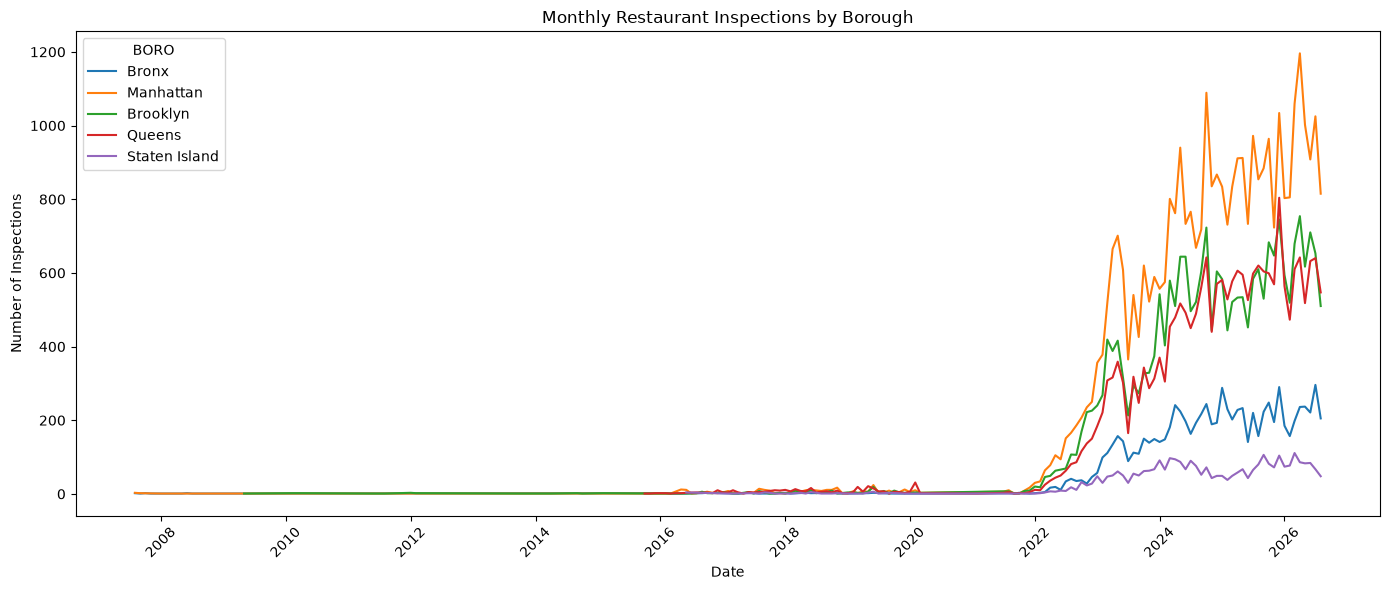

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_inspections,
    x='MONTH',
    y='MONTHLY INSPECTION COUNT',
    hue='BORO'
)

plt.title('Monthly Restaurant Inspections by Borough')
plt.xlabel('Date')
plt.ylabel('Number of Inspections')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

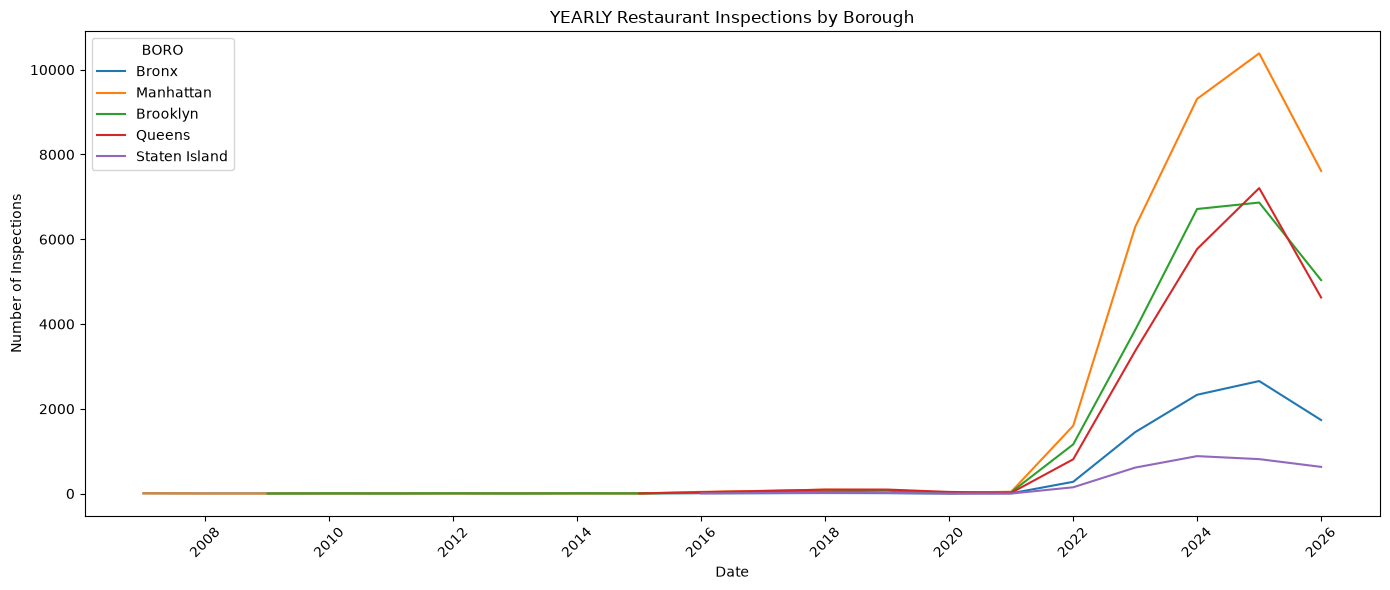

In [9]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_inspections,
    x='YEAR',
    y='YEARLY INSPECTION COUNT',
    hue='BORO'
)

plt.title('YEARLY Restaurant Inspections by Borough')
plt.xlabel('Date')
plt.ylabel('Number of Inspections')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### **Aggregated Time Series Analysis**

Each row of data represents an individual violation, thus there may be multiple rows describing different violations for the same inspection of a singluar restaurant. Monthly inspections prior to late 2022 are relatively low in comparison to after, so the time series model will model Jan 2023 - Jul 2026. This time period has more inspections per month, allowing for forecasting analysis to be more accurate.

tldr; coverage pre-2023 is too sparse, risking large swings on monthly averages and interpolation on missing monthly data could alter the analysis

In [10]:
plt.rcParams['figure.figsize'] = (20, 15)

This one is for score and when inspections are occuring.

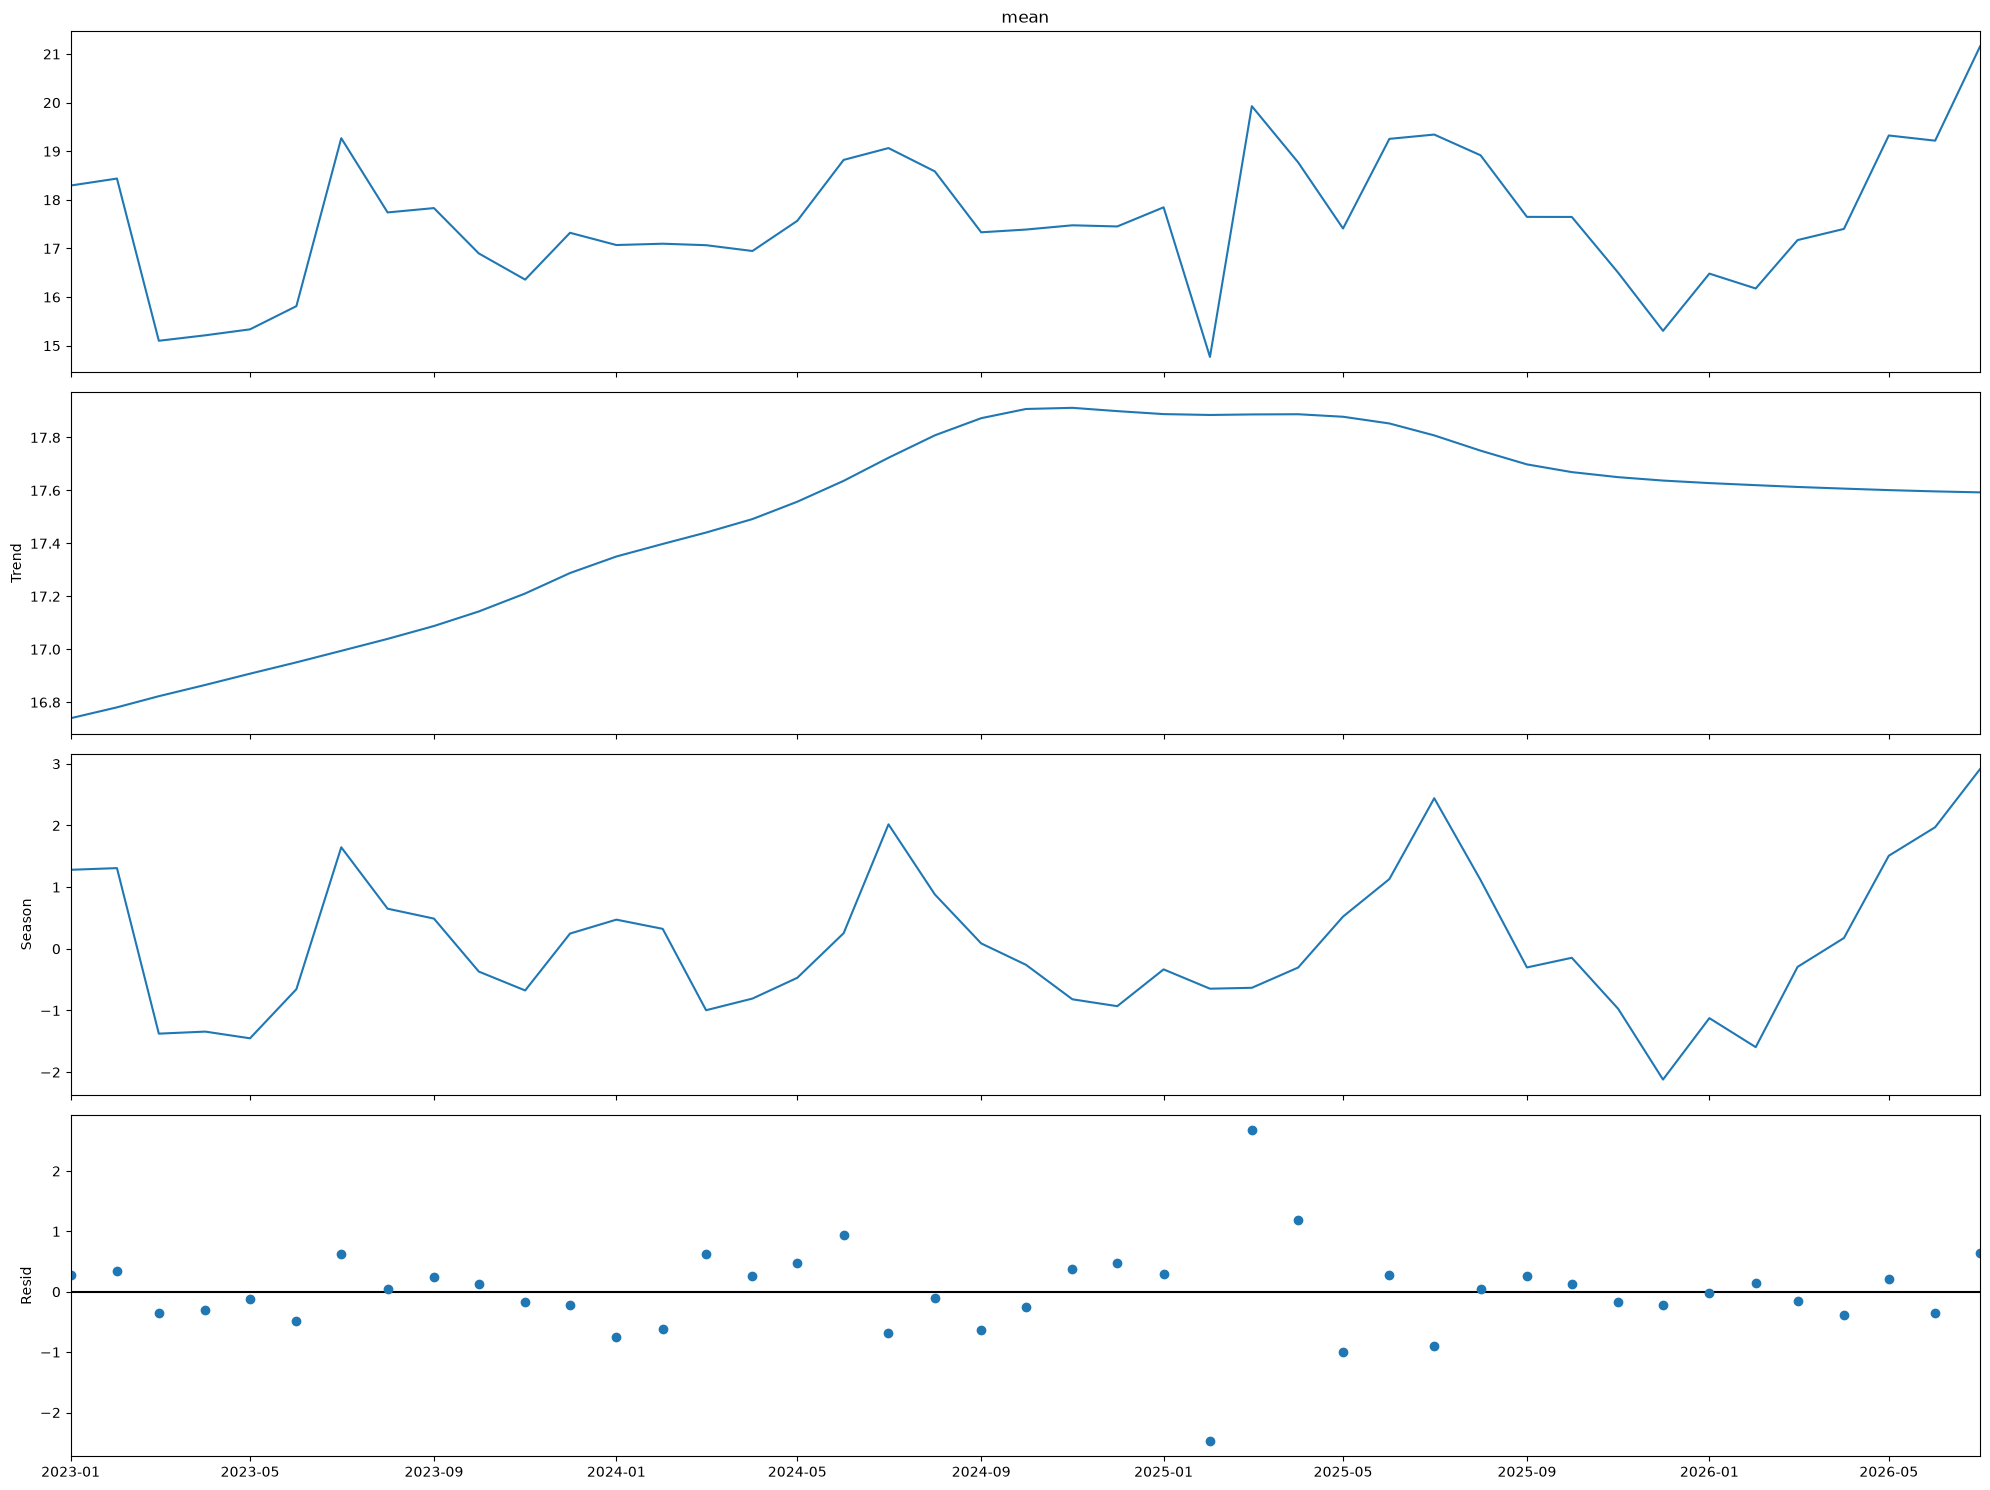

In [ ]:
ins = ts_df.copy()
ins = ins.rename(columns={'INSPECTION TYPE': 'TYPE'})

main = ins[ins['TYPE'].eq('Cycle Inspection / Initial Inspection')
           & ins['INSPECTION DATE'].between('2023-01-01','2026-07-31')
           & ins['SCORE'].notna()].copy()
main['MONTH'] = main['INSPECTION DATE'].dt.to_period('M').dt.to_timestamp()

monthly = main.groupby('MONTH')['SCORE'].agg(['mean','median','size'])

from statsmodels.tsa.seasonal import STL
res = STL(monthly['mean'], period=12, seasonal=13, robust=True).fit()
res.plot();

**Test the drift**. 

Refitted with a specified _seasonal_degree_ hyperparameter. If the July peak stays near the same size every year, the growth in your plot was drift. If the residuals get much larger, the seasonal pattern really does change.

Found that changes to the seasonal hyperparameter did not do anything, but the seasonal_deg = 0 did.

- seasonal=13 controls the seasonal smoother's window length. A larger window generally produces a smoother seasonal estimate.
- seasonal_deg=0 means the smoother uses locally constant fits rather than locally linear fits.
- seasonal_deg=1 permits locally linear fits, potentially allowing more flexibility in the local seasonal estimate.

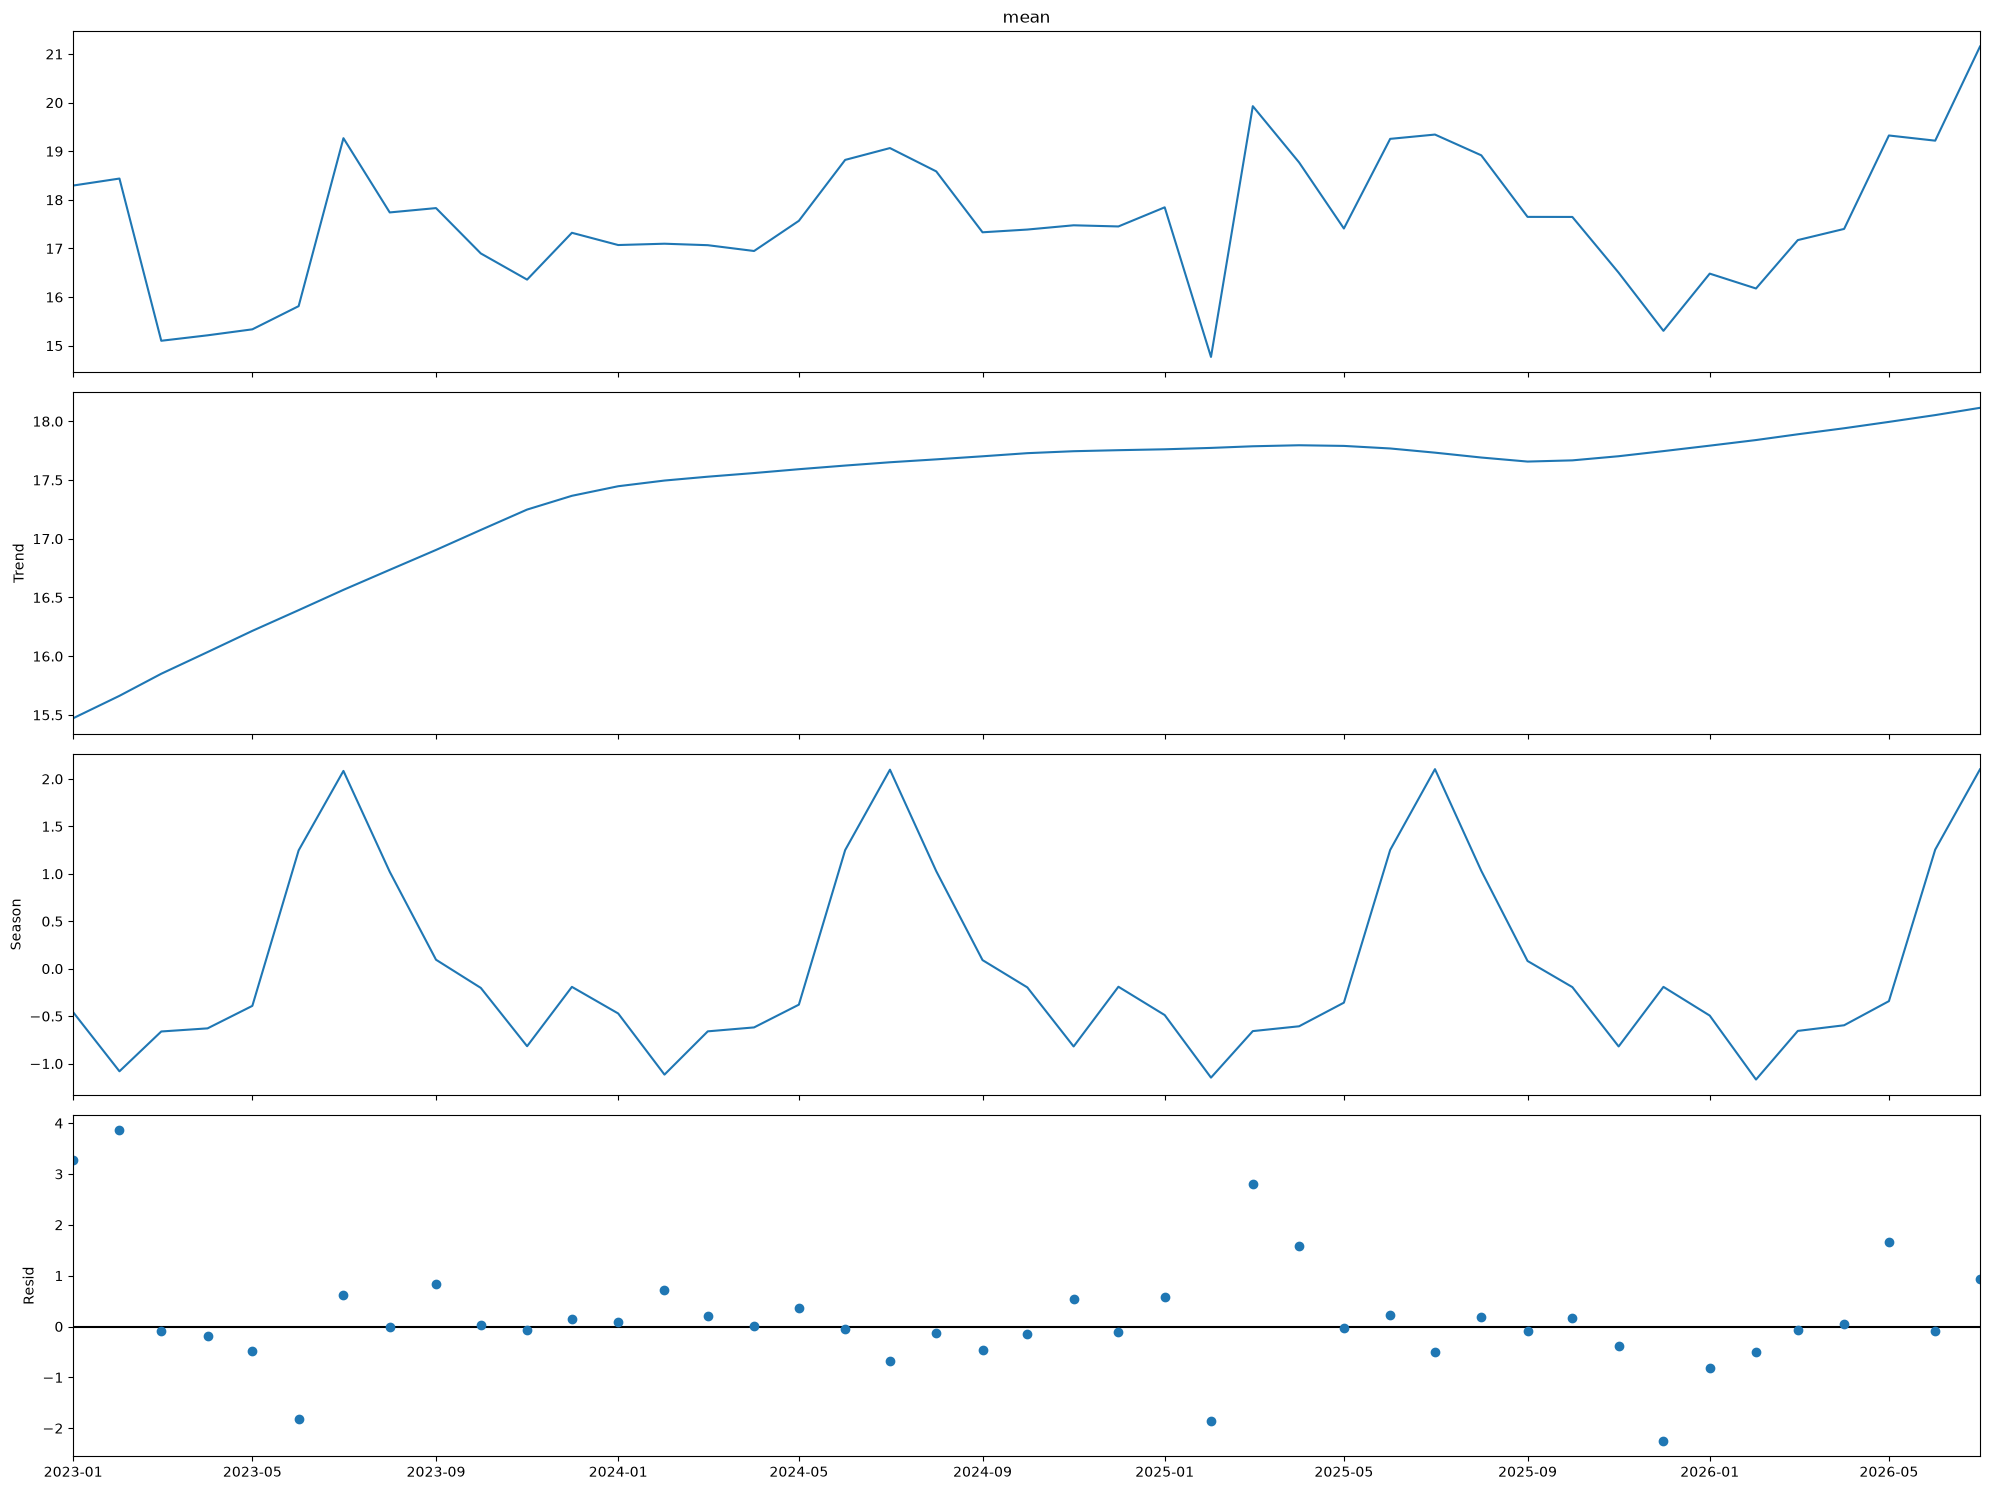

In [12]:
res = STL(monthly['mean'], period=12, seasonal=13, 
          seasonal_deg = 0, robust=True).fit()
res.plot();

**Check sensitivity**

Start the series at '2023-07-01' and see whether the trend and seasonal shapes hold.


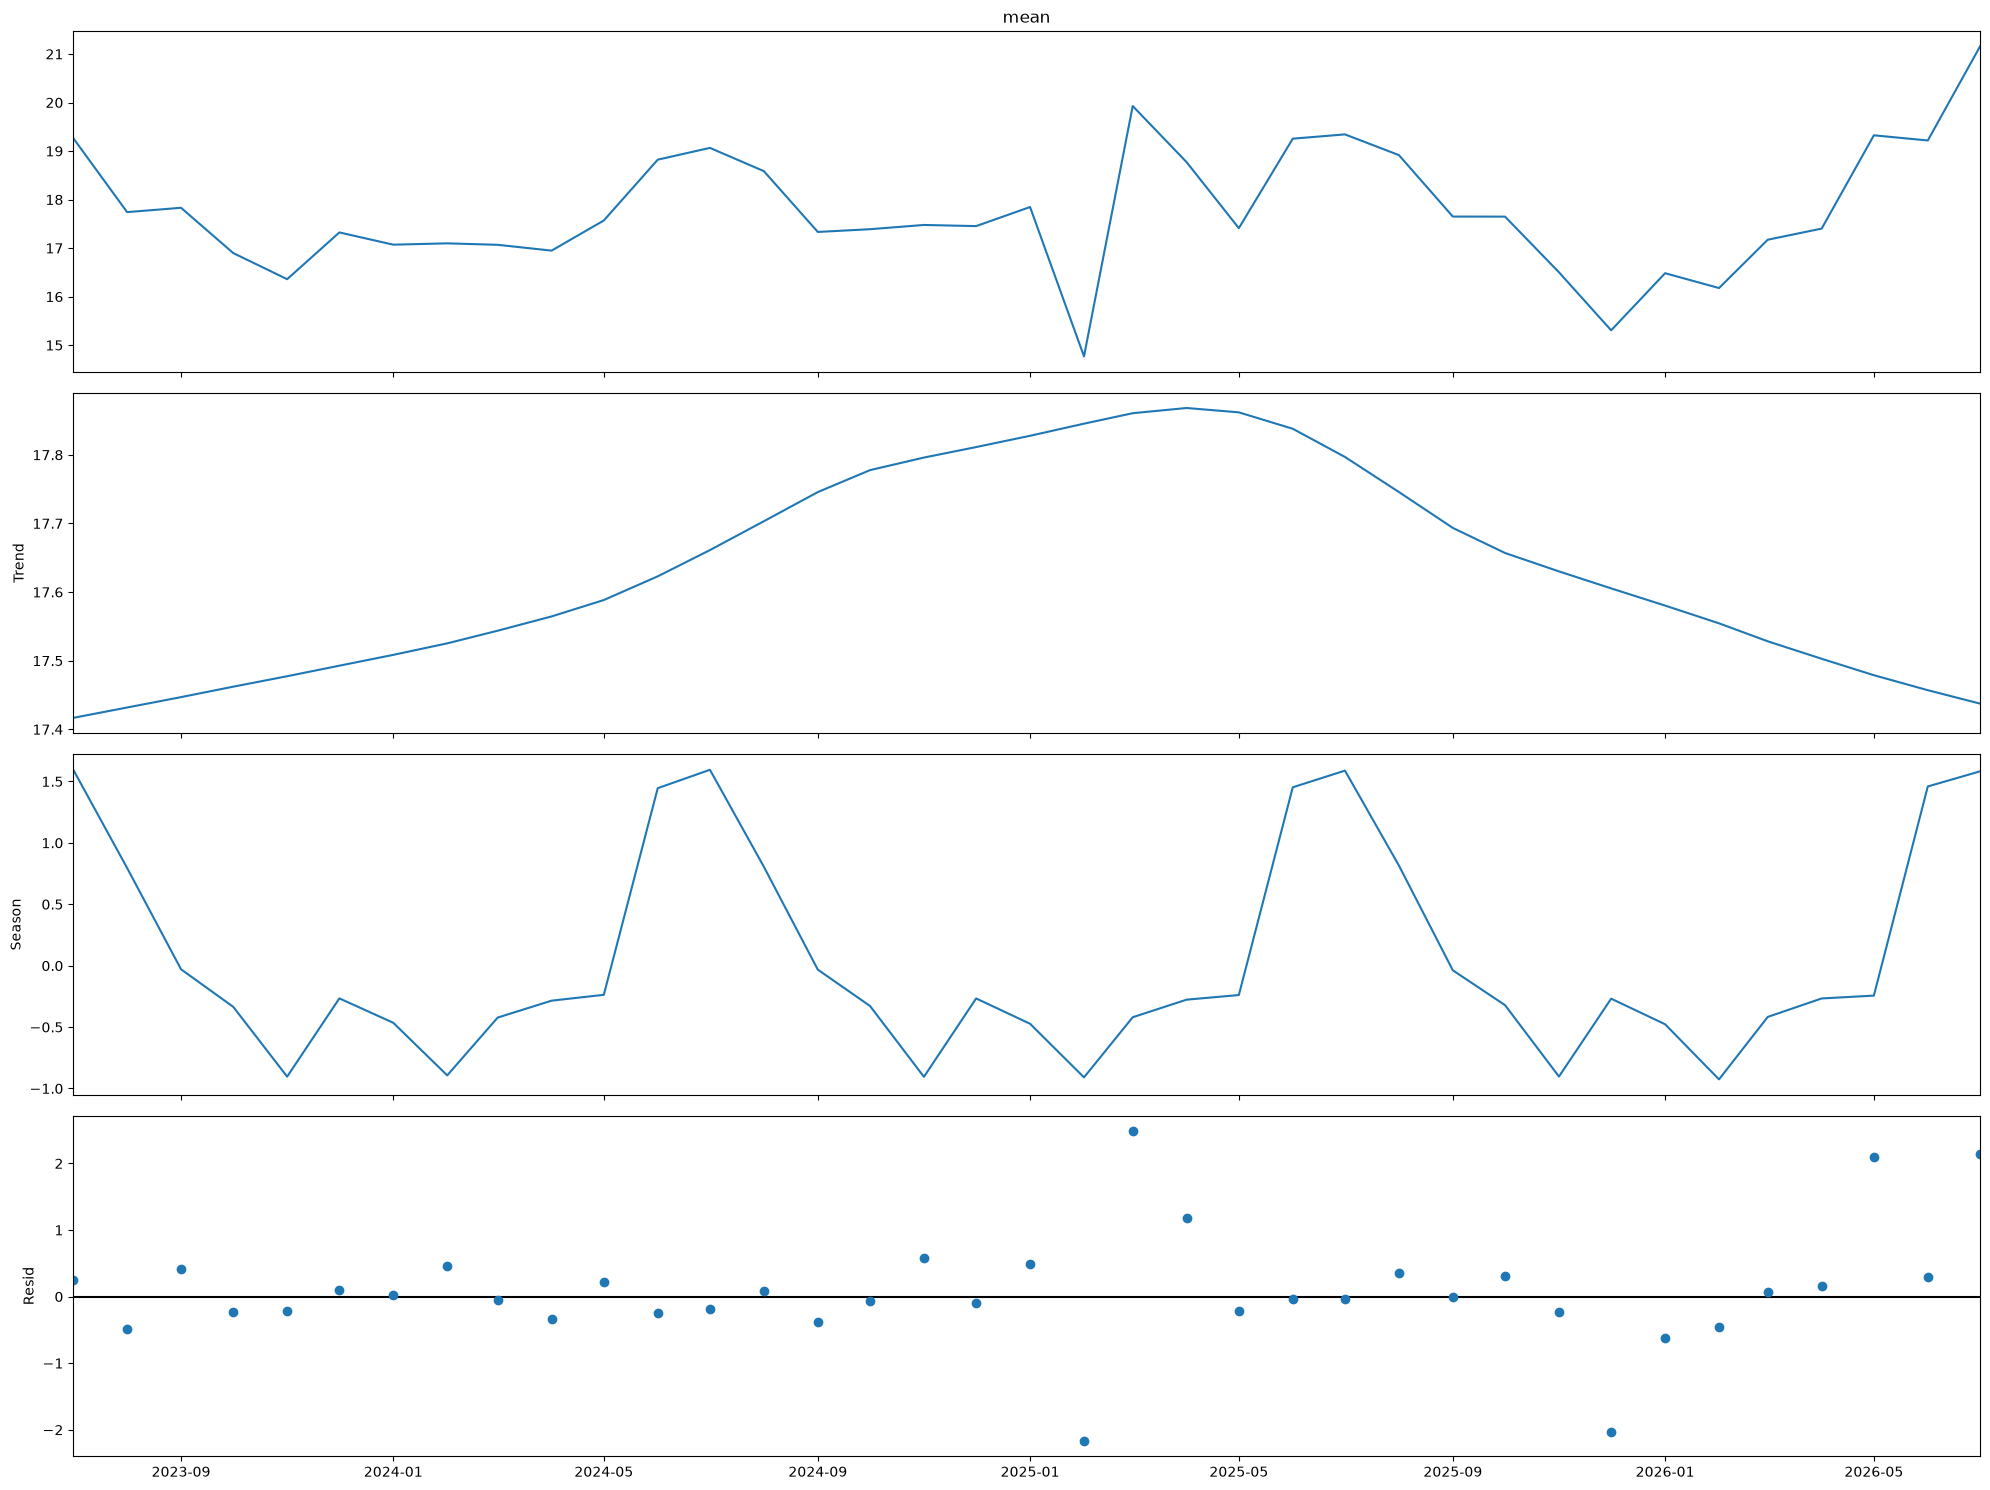

In [13]:
main2 = ins[ins['TYPE'].eq('Cycle Inspection / Initial Inspection')
           & ins['INSPECTION DATE'].between('2023-07-01','2026-07-31')
           & ins['SCORE'].notna()].copy()
main2['MONTH'] = main2['INSPECTION DATE'].dt.to_period('M').dt.to_timestamp()

monthly2 = main2.groupby('MONTH')['SCORE'].agg(['mean','median','size'])

res = STL(monthly2['mean'], period=12, seasonal=13, 
          seasonal_deg = 0, robust=True).fit()
res.plot();


- Top = score (mean)
- Trend = is compliance getting better over time?
- seasonality = is there a calendar pattern to scores or inspections? (inspections would reflect DOHMH scheduling and workload, not restaurant behavior)
- This one doesn't show anything borough related

**Investigate Feb to Mar 2025**

Compare inspection counts and the mix of inspection types for those two months against the neighboring months.

,size,mean
INSPECTION DATE,,
2025-01-05,155,21.238710
2025-01-12,290,17.986207
2025-01-19,396,19.292929
2025-01-26,126,12.753968
2025-02-02,184,10.309783
2025-02-09,101,14.900990
2025-02-16,164,16.536585
2025-02-23,91,16.450549
2025-03-02,178,17.134831


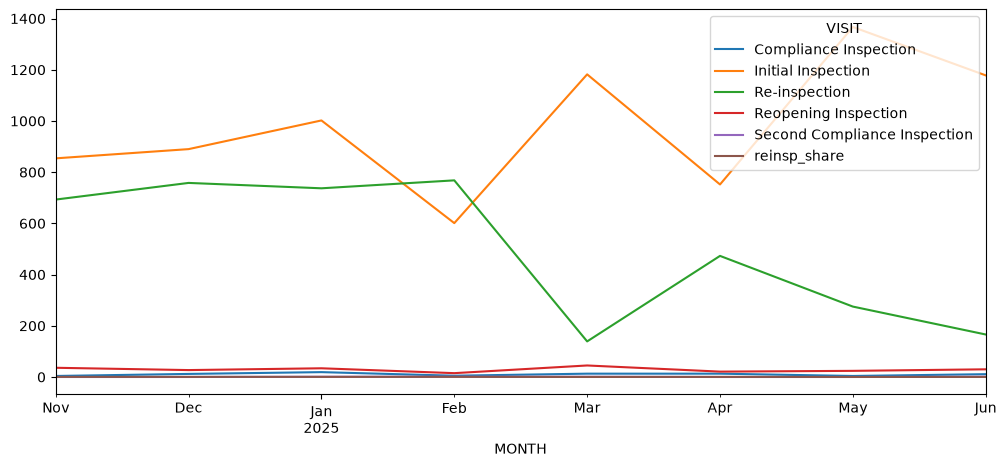

In [ ]:
import statsmodels.formula.api as smf

win = ins[ins['INSPECTION DATE'].between('2023-07-01','2026-07-31')].copy()
win['MONTH']   = win['INSPECTION DATE'].dt.to_period('M').dt.to_timestamp()
win['PROGRAM'] = win['TYPE'].str.split(' / ').str[0]
win['VISIT']   = win['TYPE'].str.split(' / ').str[1]

#Counts by visit type, and re-inspection share
cyc = win[win['PROGRAM'].eq('Cycle Inspection')]
counts = cyc.groupby(['MONTH','VISIT']).size().unstack(fill_value=0)
counts['reinsp_share'] = counts['Re-inspection'] / counts.sum(axis=1)
counts.loc['2024-11-01':'2025-06-01'].plot(figsize=(12,5))

#Score outcomes for cycle initial inspections, by month
ci = cyc[cyc['VISIT'].eq('Initial Inspection') & cyc['SCORE'].notna()].copy()
m = ci.groupby('MONTH')['SCORE'].agg(
        n='size', mean='mean', median='median',
        pct_a=lambda s: (s <= 13).mean(),
        pct_c=lambda s: (s >= 28).mean())

#Robust z-scores --> which months stand out on each metric?
rz = (m - m.median()) / (1.4826 * (m - m.median()).abs().median())
rz.loc['2025-01-01':'2025-04-01'].round(1)

#Borough mix by month
pd.crosstab(ci['MONTH'], ci['BORO'], normalize='index').loc['2024-11-01':'2025-06-01']

#Same calendar month across years
ci.groupby([ci['INSPECTION DATE'].dt.month.rename('month'),
            ci['INSPECTION DATE'].dt.year.rename('year')])['SCORE'].agg(['size','mean'])

#Where in the month did it shift? Weekly view
ci.groupby(pd.Grouper(key='INSPECTION DATE', freq='W'))['SCORE'].agg(['size','mean']).loc['2025-01-01':'2025-04-30']

Regression coefficients for feb and march of each model. Coefficients read as lower or higher than the expected value based on models seasonal baseline. Analyzing changes in average scores...

In [15]:
ci['MONTHNUM'] = ci['INSPECTION DATE'].dt.month
ci['FEB25'] = (ci['MONTH'] == '2025-02-01').astype(int)
ci['MAR25'] = (ci['MONTH'] == '2025-03-01').astype(int)
cl = dict(cov_type='cluster', cov_kwds={'groups': ci['CAMIS']})

base = smf.ols('SCORE ~ C(MONTHNUM) + FEB25 + MAR25', ci).fit(**cl)
adj  = smf.ols('SCORE ~ C(MONTHNUM) + C(BORO) + FEB25 + MAR25', ci).fit(**cl)
print(base.params[['FEB25','MAR25']], adj.params[['FEB25','MAR25']])

FEB25   -1.722651
MAR25    2.780670
dtype: float64 FEB25   -1.751993
MAR25    2.705334
dtype: float64


Examining if anomolies remain after accounting for previous inspection score. Analyzing if unusual scores during feb/march reflect a broader anomaly or if it is explainable by restaurants' existing inspection histories.

In [16]:
allc = (
    ins[ins['TYPE'].str.startswith('Cycle Inspection') & ins['SCORE'].notna()]
    .sort_values(['CAMIS', 'INSPECTION DATE'])
    .copy()
)

allc['PRIOR_SCORE'] = allc.groupby('CAMIS')['SCORE'].shift(1)

ci2 = (
    ci.merge(
        allc[['CAMIS', 'INSPECTION DATE', 'PRIOR_SCORE']],
        on=['CAMIS', 'INSPECTION DATE'],
        how='left'
    )
    .dropna(subset=['PRIOR_SCORE'])
)

cl2 = dict(cov_type='cluster', cov_kwds={'groups': ci2['CAMIS']})

base_prior = smf.ols(
    'SCORE ~ C(MONTHNUM) + FEB25 + MAR25',
    ci2
).fit(**cl2)

adj_prior = smf.ols(
    'SCORE ~ C(MONTHNUM) + C(BORO) + FEB25 + MAR25 + PRIOR_SCORE',
    ci2
).fit(**cl2)

print("Without prior score:")
print(base_prior.params[['FEB25', 'MAR25']])

print("\nWith prior score and borough:")
print(adj_prior.params[['FEB25', 'MAR25']])

Without prior score:
FEB25   -2.037575
MAR25    3.644176
dtype: float64

With prior score and borough:
FEB25   -1.315050
MAR25    1.443529
dtype: float64


In [17]:
print('rows used:', len(ci2))

cmp = pd.DataFrame({
    'month_only':   base_prior.params,
    'with_prior':   adj.params,
    'p_month_only': base_prior.pvalues,
    'p_with_prior': adj.pvalues,
}).round(3)
print(cmp)

rows used: 24757
                          month_only  with_prior  p_month_only  p_with_prior
C(BORO)[T.Brooklyn]              NaN      -0.009           NaN         0.975
C(BORO)[T.Manhattan]             NaN      -0.458           NaN         0.084
C(BORO)[T.Queens]                NaN       1.320           NaN         0.000
C(BORO)[T.Staten Island]         NaN      -0.555           NaN         0.189
C(MONTHNUM)[T.10]              0.963       0.319         0.014         0.309
C(MONTHNUM)[T.11]              0.081      -0.309         0.846         0.349
C(MONTHNUM)[T.12]             -0.625      -0.544         0.112         0.092
C(MONTHNUM)[T.2]              -0.091      -0.615         0.839         0.098
C(MONTHNUM)[T.3]               0.258       0.072         0.546         0.845
C(MONTHNUM)[T.4]               1.227       0.503         0.002         0.122
C(MONTHNUM)[T.5]               1.367       0.958         0.000         0.002
C(MONTHNUM)[T.6]               2.245       1.976         0.

Monthly Compliance Metrics:

What do violations and inspections tell us about month to month changes?

In [18]:
ci = ts_df[
    ts_df['INSPECTION TYPE'].eq(
        'Cycle Inspection / Initial Inspection'
    )
    & ts_df['INSPECTION DATE'].between(
        '2023-01-01', '2026-07-31'
    )
    & ts_df['SCORE'].notna()
].copy()

ci['MONTH'] = (
    ci['INSPECTION DATE']
    .dt.to_period('M')
    .dt.to_timestamp()
)

ci['MONTHNUM'] = ci['INSPECTION DATE'].dt.month
ci['YEAR'] = ci['INSPECTION DATE'].dt.year

# Rename aggregated metrics to names used in the rest of your notebook
ci['VIOLATION_COUNT'] = ci['violation_record_count']

ci['CRITICAL_ANY'] = (
    ci['critical_violation_count'] > 0
)

print(f"Total inspections: {len(ci):,}")
print(f"Unique restaurants: {ci['CAMIS'].nunique():,}")

Total inspections: 42,722
Unique restaurants: 21,716


In [19]:
#calculating monthly compliance metrics
monthly_metrics = (
    ci.groupby('MONTH')
    .agg(
        INSPECTIONS=('CAMIS', 'size'),
        UNIQUE_RESTAURANTS=('CAMIS', 'nunique'),
        MEAN_SCORE=('SCORE', 'mean'),
        MEDIAN_SCORE=('SCORE', 'median'),
        SCORE_STD=('SCORE', 'std'),
        PCT_A=('SCORE', lambda x: (x <= 13).mean() * 100),
        PCT_C=('SCORE', lambda x: (x >= 28).mean() * 100),
        PCT_CRITICAL=('CRITICAL_ANY', 'mean'),
        AVG_VIOLATIONS=('VIOLATION_COUNT', 'mean')
    )
)

monthly_metrics['PCT_CRITICAL'] *= 100

monthly_metrics.head()

,INSPECTIONS,UNIQUE_RESTAURANTS,MEAN_SCORE,MEDIAN_SCORE,SCORE_STD,PCT_A,PCT_C,PCT_CRITICAL,AVG_VIOLATIONS
MONTH,,,,,,,,,
2023-01-01,309,309,18.294498,13.0,13.461851,55.016181,20.064725,90.614887,3.511327
2023-02-01,420,420,18.438095,13.0,12.529239,51.428571,19.761905,91.190476,3.571429
2023-03-01,771,771,15.101167,12.0,11.928799,66.796368,12.451362,84.435798,2.997406
2023-04-01,966,966,15.213251,12.0,11.513366,65.527950,13.561077,83.540373,3.010352
2023-05-01,1189,1189,15.336417,12.0,10.891856,64.087468,13.204373,85.365854,2.989907


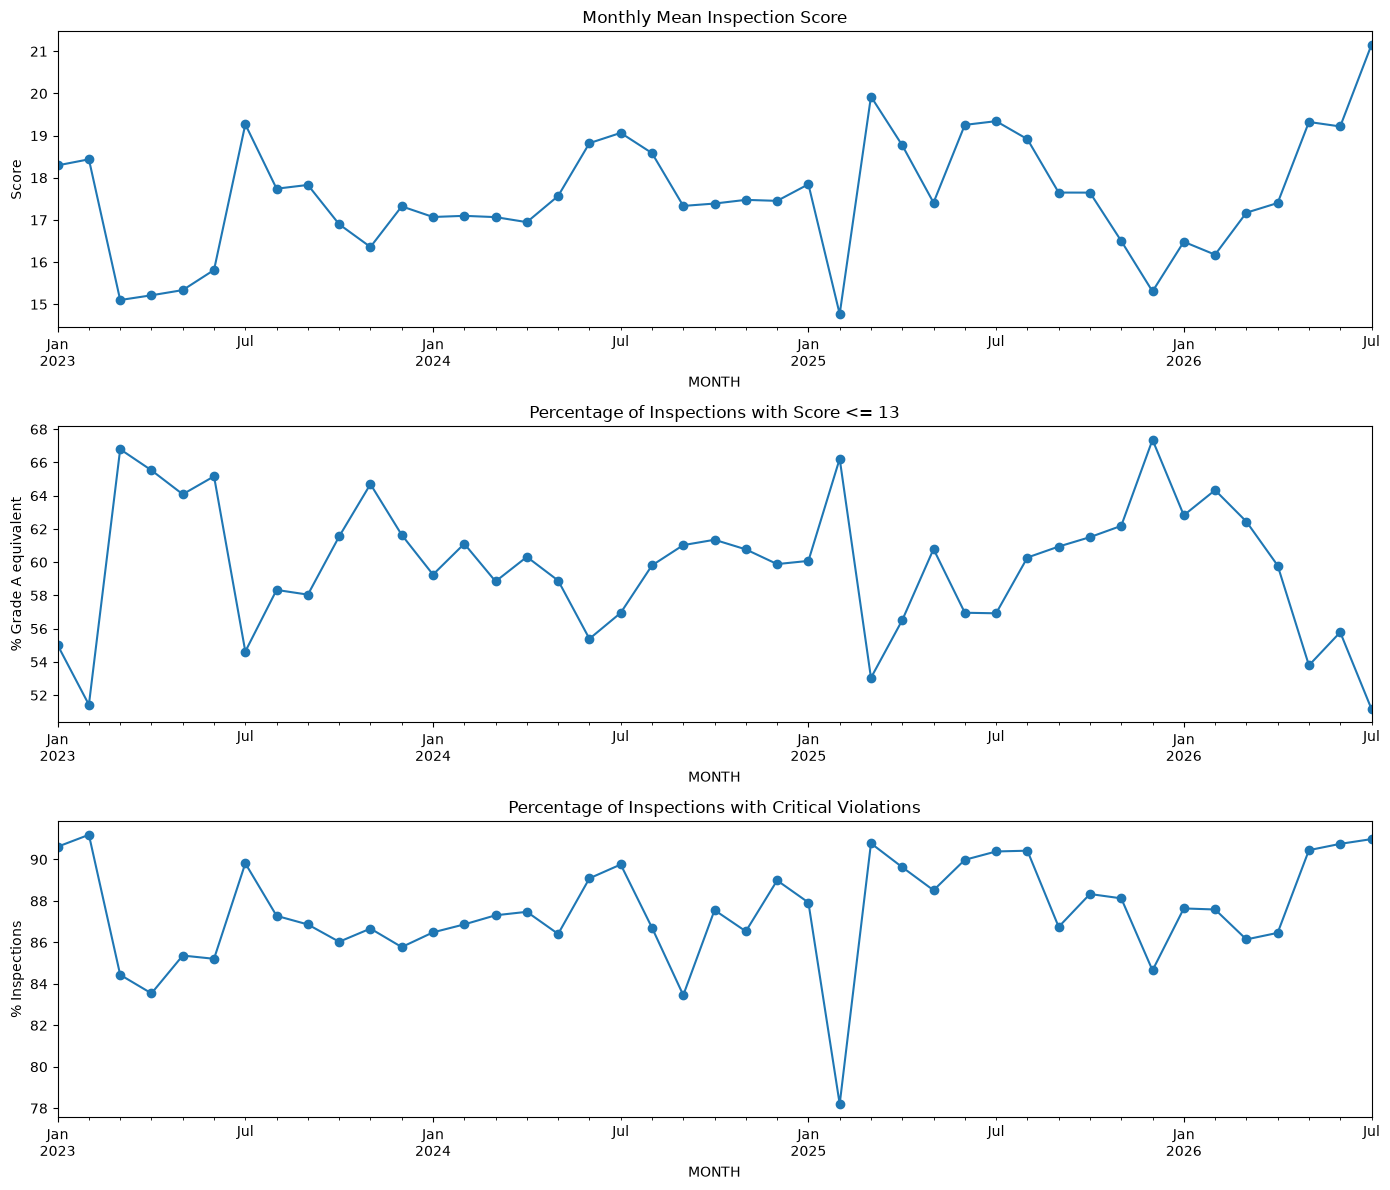

In [20]:
#visualizing monthly metrics
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

monthly_metrics['MEAN_SCORE'].plot(
    ax=axes[0], marker='o'
)
axes[0].set_title('Monthly Mean Inspection Score')
axes[0].set_ylabel('Score')

monthly_metrics['PCT_A'].plot(
    ax=axes[1], marker='o'
)
axes[1].set_title('Percentage of Inspections with Score <= 13')
axes[1].set_ylabel('% Grade A equivalent')

monthly_metrics['PCT_CRITICAL'].plot(
    ax=axes[2], marker='o'
)
axes[2].set_title('Percentage of Inspections with Critical Violations')
axes[2].set_ylabel('% Inspections')

plt.tight_layout()
plt.show()

- Mean score and A-grade-equivalent has a negative relationship, when one goes up the other goes down. Higher scores = less A-grade-equivalent. This makes sense as the higher a score, the worse the inspection score.
- Are critical violation rates following the same seasonal pattern?
- Critical violation rates also appear to reinforce this finding. When the % of inspections with critical violations increases, the % of A-grade-equivalents decrease. This also correlates with higher scores. % of critical violations and score averages have a positive relationship, and they both have negative relationships with % of A-grade-equivalents.

Borough-level differences

In [ ]:
#borough differences
#descriptive comparison across boroughs
borough_metrics = (
    ci.groupby('BORO')
    .agg(
        INSPECTIONS=('CAMIS', 'size'),
        RESTAURANTS=('CAMIS', 'nunique'),
        MEAN_SCORE=('SCORE', 'mean'),
        MEDIAN_SCORE=('SCORE', 'median'),
        SCORE_STD=('SCORE', 'std'),
        PCT_A=('SCORE', lambda x: (x <= 13).mean() * 100),
        PCT_C=('SCORE', lambda x: (x >= 28).mean() * 100),
        PCT_CRITICAL=('CRITICAL_ANY', 'mean'),
        AVG_VIOLATIONS=('VIOLATION_COUNT', 'mean')
    )
    .sort_values('MEAN_SCORE', ascending=False)
)

borough_metrics['PCT_CRITICAL'] *= 100

borough_metrics.round(2)

,INSPECTIONS,RESTAURANTS,MEAN_SCORE,MEDIAN_SCORE,SCORE_STD,PCT_A,PCT_C,PCT_CRITICAL,AVG_VIOLATIONS
BORO,,,,,,,,,
Queens,9827,4905,18.81,13.0,14.28,56.99,21.46,89.23,3.59
Brooklyn,10979,5511,17.60,12.0,14.21,60.95,18.21,86.67,3.31
Bronx,4105,1985,17.49,13.0,12.94,58.12,16.57,88.23,3.40
Manhattan,16241,8522,17.00,12.0,13.30,61.99,16.61,86.93,3.28
Staten Island,1570,793,16.99,13.0,11.44,55.22,14.46,89.30,3.19


In [22]:
#borough regression for controlling month/year
import statsmodels.formula.api as smf

borough_model = smf.ols(
    'SCORE ~ C(BORO) + C(MONTHNUM) + C(YEAR)',
    data=ci
).fit(
    cov_type='cluster',
    cov_kwds={'groups': ci['CAMIS']}
)

print(borough_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  SCORE   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     17.27
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           7.81e-55
Time:                        16:49:21   Log-Likelihood:            -1.7223e+05
No. Observations:               42722   AIC:                         3.445e+05
Df Residuals:                   42703   BIC:                         3.447e+05
Df Model:                          18                                         
Covariance Type:              cluster                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

What is being measured?
- C(BORO) measures geographical differences.
- C(MONTHNUM) controls for seasonality.
- C(YEAR) controls for annual changes.
- Clustering standard errors by CAMIS accounts for restaurants appearing multiple times.

In [23]:
#making manhattan the reference borough
borough_model = smf.ols(
    'SCORE ~ C(BORO, Treatment(reference="Manhattan"))'
    ' + C(MONTHNUM) + C(YEAR)',
    data=ci
).fit(
    cov_type='cluster',
    cov_kwds={'groups': ci['CAMIS']}
)

borough_effects = borough_model.params.filter(
    like='BORO'
)

borough_ci = borough_model.conf_int().loc[
    borough_effects.index
]

borough_results = pd.DataFrame({
    'Effect_vs_Manhattan': borough_effects,
    'Lower_95_CI': borough_ci[0],
    'Upper_95_CI': borough_ci[1],
    'P_Value': borough_model.pvalues[borough_effects.index]
})

borough_results.round(3)

,Effect_vs_Manhattan,Lower_95_CI,Upper_95_CI,P_Value
"C(BORO, Treatment(reference=""Manhattan""))[T.Bronx]",0.499,0.003,0.996,0.049
"C(BORO, Treatment(reference=""Manhattan""))[T.Brooklyn]",0.607,0.226,0.987,0.002
"C(BORO, Treatment(reference=""Manhattan""))[T.Queens]",1.796,1.381,2.210,0.000
"C(BORO, Treatment(reference=""Manhattan""))[T.Staten Island]",0.044,-0.639,0.728,0.899


After controlling for year and month, Queens restaurants had inspection scores X points higher than Manhattan restaurants. Since higher scores indicate more violations, this suggests relatively worse inspection outcomes in Queens during the study period.

In [24]:
#testing whether borough membership is collectively significant
borough_model.f_test(
    'C(BORO, Treatment(reference="Manhattan"))[T.Bronx] = 0, '
    'C(BORO, Treatment(reference="Manhattan"))[T.Brooklyn] = 0, '
    'C(BORO, Treatment(reference="Manhattan"))[T.Queens] = 0, '
    'C(BORO, Treatment(reference="Manhattan"))[T.Staten Island] = 0'
)

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=18.665215887005736, p=2.4974606299903523e-15, df_denom=2.17e+04, df_num=4>

This tests whether borough membership has any overall relationship with scores after controlling for month and year.

If the test is significant, you have stronger evidence of geographical differences.

Zip-code level Analysis

In [ ]:
#zip-code geographical analysis
zip_metrics = (
    ci.dropna(subset=['ZIPCODE'])
    .groupby('ZIPCODE')
    .agg(
        INSPECTIONS=('CAMIS', 'size'),
        RESTAURANTS=('CAMIS', 'nunique'),
        MEAN_SCORE=('SCORE', 'mean'),
        MEDIAN_SCORE=('SCORE', 'median'),
        PCT_A=('SCORE', lambda x: (x <= 13).mean() * 100),
        PCT_C=('SCORE', lambda x: (x >= 28).mean() * 100),
        PCT_CRITICAL=('CRITICAL_ANY', 'mean'),
        AVG_VIOLATIONS=('VIOLATION_COUNT', 'mean')
    )
)

zip_metrics['PCT_CRITICAL'] *= 100

#Restrict to ZIP codes with at least 30 inspections, 
#can test 20, 50, 100 to see how rankings change
zip_metrics_filtered = zip_metrics[
    zip_metrics['INSPECTIONS'] >= 30
].copy()

zip_metrics_filtered = zip_metrics_filtered.sort_values(
    'MEAN_SCORE', ascending=False
)

zip_metrics_filtered.round(2)

,INSPECTIONS,RESTAURANTS,MEAN_SCORE,MEDIAN_SCORE,PCT_A,PCT_C,PCT_CRITICAL,AVG_VIOLATIONS
ZIPCODE,,,,,,,,
11355.0,281,146,25.49,22.0,38.43,36.30,95.73,4.59
11419.0,188,83,22.36,18.0,45.21,30.32,90.96,4.23
11372.0,598,286,22.25,17.0,47.49,30.27,94.98,4.11
11354.0,657,340,21.67,18.0,46.12,28.46,92.85,4.03
10470.0,74,35,21.42,18.0,45.95,27.03,94.59,3.80
...,...,...,...,...,...,...,...,...
10309.0,128,60,13.79,12.0,67.97,7.81,82.03,2.66
10281.0,34,18,11.88,9.5,73.53,2.94,70.59,2.50
11693.0,51,26,10.98,9.0,78.43,9.80,76.47,2.45


The minimum of 30 inspections is a reasonable starting point, but you can test thresholds of 20, 50, or 100 and see how the rankings change.

In [26]:
#top/bottom zip codes
print("ZIP codes with highest average inspection scores:")
display(
    zip_metrics_filtered.head(15).round(2)
)

print("ZIP codes with lowest average inspection scores:")
display(
    zip_metrics_filtered.tail(15).sort_values(
        'MEAN_SCORE'
    ).round(2)
)

ZIP codes with highest average inspection scores:


,INSPECTIONS,RESTAURANTS,MEAN_SCORE,MEDIAN_SCORE,PCT_A,PCT_C,PCT_CRITICAL,AVG_VIOLATIONS
ZIPCODE,,,,,,,,
11355.0,281,146,25.49,22.0,38.43,36.30,95.73,4.59
11419.0,188,83,22.36,18.0,45.21,30.32,90.96,4.23
11372.0,598,286,22.25,17.0,47.49,30.27,94.98,4.11
11354.0,657,340,21.67,18.0,46.12,28.46,92.85,4.03
10470.0,74,35,21.42,18.0,45.95,27.03,94.59,3.80
11203.0,209,92,21.27,13.0,54.07,26.32,89.95,3.71
10040.0,103,57,20.99,16.0,45.63,27.18,87.38,3.67
11221.0,238,126,20.95,13.0,56.72,23.95,88.66,3.61
10454.0,141,71,20.73,13.0,51.77,21.99,89.36,3.94


ZIP codes with lowest average inspection scores:


,INSPECTIONS,RESTAURANTS,MEAN_SCORE,MEDIAN_SCORE,PCT_A,PCT_C,PCT_CRITICAL,AVG_VIOLATIONS
ZIPCODE,,,,,,,,
10121.0,165,84,4.97,2.0,92.73,3.64,30.91,1.48
11430.0,116,68,9.72,8.5,87.93,3.45,68.97,2.18
11693.0,51,26,10.98,9.0,78.43,9.80,76.47,2.45
10281.0,34,18,11.88,9.5,73.53,2.94,70.59,2.50
10309.0,128,60,13.79,12.0,67.97,7.81,82.03,2.66
10464.0,56,26,13.84,12.0,75.00,5.36,87.50,3.14
10020.0,55,31,14.18,11.0,76.36,12.73,83.64,2.84
10451.0,228,132,14.23,11.0,65.35,10.53,74.56,2.95
10460.0,124,54,14.46,12.0,67.74,12.90,77.42,2.98


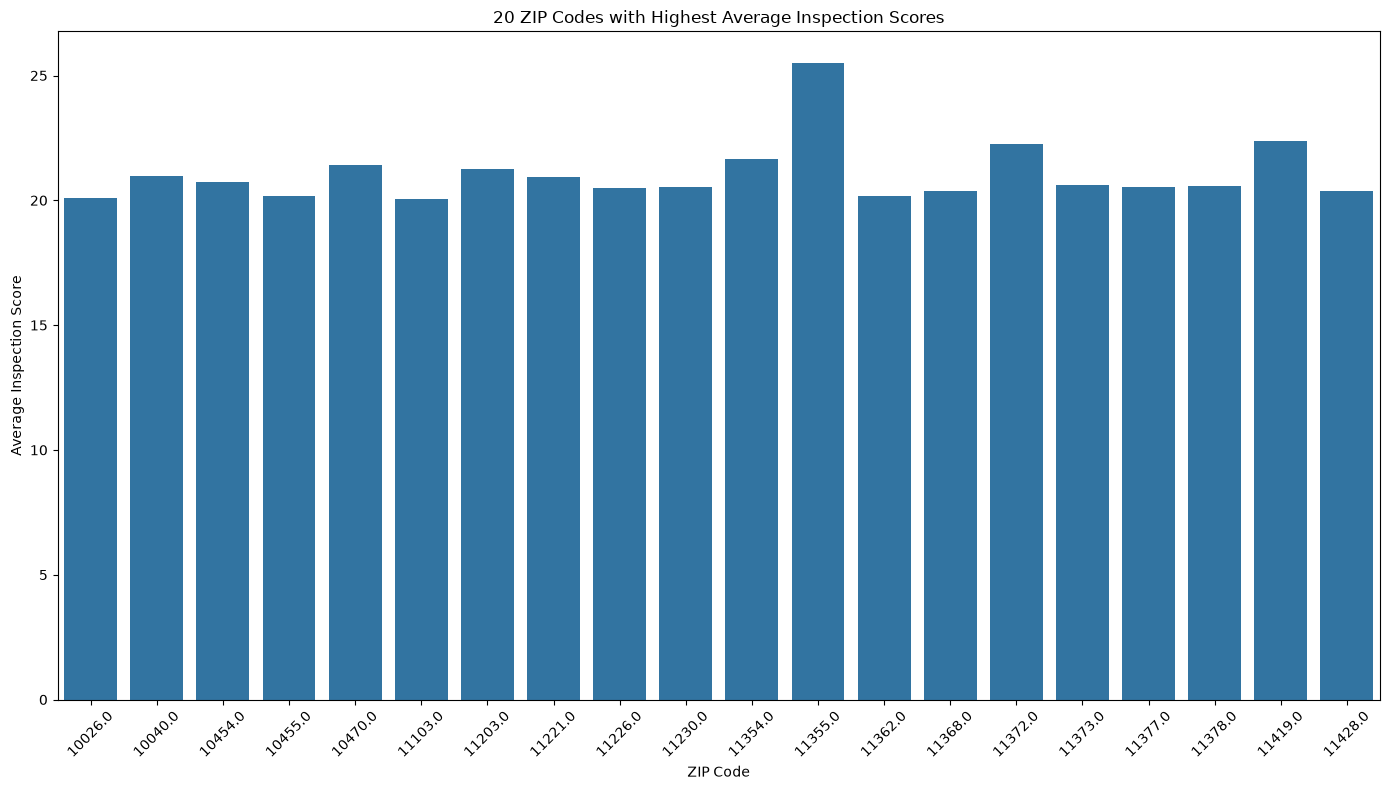

In [27]:
#visualize zip-code differences
plt.figure(figsize=(14, 8))

sns.barplot(
    data=zip_metrics_filtered.head(20).reset_index(),
    x='ZIPCODE',
    y='MEAN_SCORE'
)

plt.title('20 ZIP Codes with Highest Average Inspection Scores')
plt.xlabel('ZIP Code')
plt.ylabel('Average Inspection Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
#this is the map ready dataset
zip_map_data = zip_metrics_filtered.reset_index()

zip_map_data.to_csv(
    'data/nyc_zipcode_inspection_metrics.csv',
    index=False
)

print("Map-ready dataset saved.")

Map-ready dataset saved.


Creating chloropleth diagrams

In [ ]:
#loading boundary csv
import pandas as pd
import geopandas as gpd
from shapely import wkt

#Load geographic boundary CSV
zip_boundaries = pd.read_csv(
    "data/ZIP_Code_Tabulation_Areas_20261123.csv"
)

#Convert geometry strings into actual geometric objects
zip_boundaries['Geometry'] = zip_boundaries['Geometry'].apply(
    wkt.loads
)

#Convert to GeoDataFrame
zip_geo = gpd.GeoDataFrame(
    zip_boundaries,
    geometry='Geometry',
    crs='EPSG:4326'
)

#Standardize ZIP codes
zip_geo['ZIPCODE'] = (
    zip_geo['Zip Code']
    .astype(str)
    .str.zfill(5)
)

zip_geo.head()

,Zip Code,Land Area,Water Area,Center Latitude,Center Longitude,Internal Latitude,Internal Longitude,Geometry,ZIPCODE
0,7305,14763292,13239409,40.693050,-74.069322,40.693004,-74.069650,"MULTIPOLYGON (((-74.0472 40.69079, -74.04719 4...",07305
1,10001,1616221,0,40.750649,-73.997298,40.750649,-73.997298,"MULTIPOLYGON (((-74.00998 40.7526, -74.00849 4...",10001
2,10002,2129725,0,40.715969,-73.986895,40.715969,-73.986895,"MULTIPOLYGON (((-73.99709 40.71462, -73.99681 ...",10002
3,10003,1480728,0,40.731865,-73.989124,40.731865,-73.989124,"MULTIPOLYGON (((-73.99911 40.73163, -73.99861 ...",10003
4,10004,1179938,0,40.693981,-74.018256,40.689805,-74.017389,"MULTIPOLYGON (((-74.02645 40.68614, -74.02621 ...",10004


In [30]:
#merging zipcode dataframe and new zipcode csv
zip_metrics = zip_metrics_filtered.reset_index()

zip_metrics['ZIPCODE'] = (
    zip_metrics['ZIPCODE']
    .astype(str)
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(5)
)

map_df = zip_geo.merge(
    zip_metrics,
    on='ZIPCODE',
    how='left'
)

In [31]:
nyc_zips = zip_metrics['ZIPCODE'].unique()

map_df = zip_geo[
    zip_geo['ZIPCODE'].isin(nyc_zips)
].merge(
    zip_metrics,
    on='ZIPCODE',
    how='left'
)

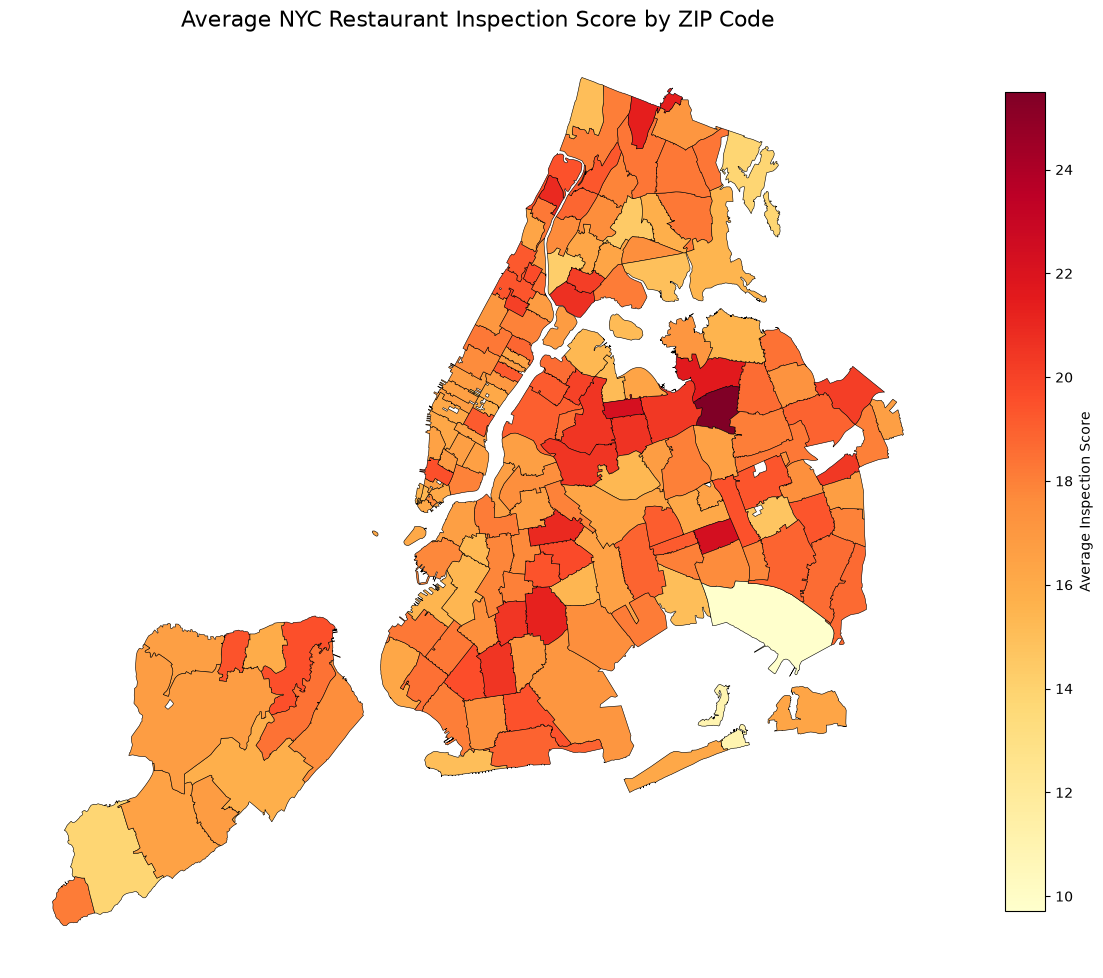

In [32]:
#plotting map
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

map_df.plot(
    column='MEAN_SCORE',
    cmap='YlOrRd',
    linewidth=0.4,
    edgecolor='black',
    legend=True,
    ax=ax,
    missing_kwds={
        'color': 'lightgray',
        'label': 'No data'
    },
    legend_kwds={
        'label': 'Average Inspection Score',
        'shrink': 0.7
    }
)

ax.set_title(
    'Average NYC Restaurant Inspection Score by ZIP Code',
    fontsize=16
)

ax.axis('off')

plt.tight_layout()
plt.show()

#### Are the same restaurants improving/worsening?

In [ ]:
#restaurant-level inspection history
restaurant_history = (
    ci.sort_values(['CAMIS', 'INSPECTION DATE'])
    .groupby('CAMIS')
    .agg(
        INSPECTION_COUNT=('SCORE', 'size'),
        FIRST_DATE=('INSPECTION DATE', 'min'),
        LAST_DATE=('INSPECTION DATE', 'max'),
        FIRST_SCORE=('SCORE', 'first'),
        LAST_SCORE=('SCORE', 'last'),
        MEAN_SCORE=('SCORE', 'mean'),
        MEDIAN_SCORE=('SCORE', 'median'),
        BORO=('BORO', 'first')
    )
)

restaurant_history['SCORE_CHANGE'] = (
    restaurant_history['LAST_SCORE']
    - restaurant_history['FIRST_SCORE']
)

restaurant_history['DAYS_OBSERVED'] = (
    restaurant_history['LAST_DATE']
    - restaurant_history['FIRST_DATE']
).dt.days

#Restaurants inspected at least twice
repeated = restaurant_history[
    restaurant_history['INSPECTION_COUNT'] >= 2
].copy()

repeated.head()

,INSPECTION_COUNT,FIRST_DATE,LAST_DATE,FIRST_SCORE,LAST_SCORE,MEAN_SCORE,MEDIAN_SCORE,BORO,SCORE_CHANGE,DAYS_OBSERVED
CAMIS,,,,,,,,,,
30075445,3,2023-08-01,2026-02-27,38.0,7.0,18.333333,10.0,Bronx,-31.0,941
30191841,2,2024-11-20,2026-07-30,24.0,13.0,18.500000,18.5,Manhattan,-11.0,617
40356483,3,2023-11-16,2026-06-10,35.0,12.0,19.666667,12.0,Brooklyn,-23.0,937
40356731,3,2024-04-08,2026-06-25,12.0,5.0,9.666667,12.0,Brooklyn,-7.0,808
40357217,2,2024-05-21,2025-10-20,12.0,12.0,12.000000,12.0,Bronx,0.0,517


In [34]:
#overall improvement or deterioration
print(f"Restaurants with multiple inspections: {len(repeated):,}")

print(
    f"Average score change: "
    f"{repeated['SCORE_CHANGE'].mean():.2f}"
)

print(
    f"Median score change: "
    f"{repeated['SCORE_CHANGE'].median():.2f}"
)

print(
    f"Restaurants whose scores improved: "
    f"{(repeated['SCORE_CHANGE'] < 0).mean() * 100:.1f}%"
)

print(
    f"Restaurants whose scores worsened: "
    f"{(repeated['SCORE_CHANGE'] > 0).mean() * 100:.1f}%"
)

print(
    f"Restaurants whose scores stayed the same: "
    f"{(repeated['SCORE_CHANGE'] == 0).mean() * 100:.1f}%"
)

Restaurants with multiple inspections: 15,506
Average score change: -0.75
Median score change: 0.00
Restaurants whose scores improved: 47.3%
Restaurants whose scores worsened: 46.3%
Restaurants whose scores stayed the same: 6.4%


In [35]:
#comparing improvement across boroughs
restaurant_change_boro = (
    repeated.groupby('BORO')
    .agg(
        RESTAURANTS=('SCORE_CHANGE', 'size'),
        AVG_CHANGE=('SCORE_CHANGE', 'mean'),
        MEDIAN_CHANGE=('SCORE_CHANGE', 'median'),
        PCT_IMPROVED=('SCORE_CHANGE',
                      lambda x: (x < 0).mean() * 100),
        PCT_WORSENED=('SCORE_CHANGE',
                     lambda x: (x > 0).mean() * 100)
    )
)

restaurant_change_boro.round(2)

,RESTAURANTS,AVG_CHANGE,MEDIAN_CHANGE,PCT_IMPROVED,PCT_WORSENED
BORO,,,,,
Bronx,1488,-0.47,0.0,48.39,45.56
Brooklyn,3989,-1.49,0.0,49.21,45.32
Manhattan,5926,-0.41,0.0,46.19,46.66
Queens,3539,-0.64,0.0,46.54,46.88
Staten Island,564,-0.64,0.0,48.58,46.99


Interpretation: (higher score = worse inspection/more violations)
- Negative AVG_CHANGE: scores improved on average.
- Positive AVG_CHANGE: scores worsened on average.

In [36]:
seasonal_boro_model = smf.ols(
    'SCORE ~ C(BORO) + C(MONTHNUM)',
    data=ci
).fit(
    cov_type='cluster',
    cov_kwds={'groups': ci['CAMIS']}
)

print(seasonal_boro_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  SCORE   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     17.30
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           2.76e-46
Time:                        16:49:22   Log-Likelihood:            -1.7225e+05
No. Observations:               42722   AIC:                         3.445e+05
Df Residuals:                   42706   BIC:                         3.447e+05
Df Model:                          15                                         
Covariance Type:              cluster                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

In [37]:
#borough x month interaction model
#bronx becomes basline
seasonal_boro_model = smf.ols(
    'SCORE ~ C(BORO) * C(MONTHNUM) + C(YEAR)',
    data=ci
).fit(
    cov_type='cluster',
    cov_kwds={'groups': ci['CAMIS']}
)

print(seasonal_boro_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  SCORE   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     5.983
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           4.30e-45
Time:                        16:49:23   Log-Likelihood:            -1.7220e+05
No. Observations:               42722   AIC:                         3.445e+05
Df Residuals:                   42659   BIC:                         3.451e+05
Df Model:                          62                                         
Covariance Type:              cluster                                         
                                                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

_Model provides supplementary analysis._

This one shows boro-related stats

In [38]:
monthly_boro = (main.groupby(['MONTH','BORO'])['SCORE'].mean()
                .unstack('BORO')
                .asfreq('MS'))
print(f"Month counts with no inspection records:\n{monthly_boro.isna().sum()}")

results = {b: STL(monthly_boro[b].interpolate(limit_direction='both'), 
                  period = 12, seasonal=13, robust = True).fit()
                  for b in monthly_boro.columns}

rows = {}
for b, r in results.items():
    profile= r.seasonal.groupby(r.seasonal.index.month).mean()
    rows[b] =  {
        "trend_change": r.trend.iloc[-1] - r.trend.iloc[0],
        "trend_strength": max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
        'season_strength': max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var()),
        'seasonal_range':  profile.max() - profile.min(),
        'peak_month':      profile.idxmax(),
        'trough_month':    profile.idxmin(),
    }
summary = pd.DataFrame(rows).T.round(2)
summary


Month counts with no inspection records:
BORO
Bronx            0
Brooklyn         0
Manhattan        0
Queens           0
Staten Island    0
dtype: int64


,trend_change,trend_strength,season_strength,seasonal_range,peak_month,trough_month
Bronx,1.60,0.03,0.31,6.05,7.0,12.0
Brooklyn,-0.09,0.05,0.49,3.79,7.0,11.0
Manhattan,0.75,0.03,0.23,5.71,7.0,3.0
Queens,2.24,0.43,0.42,3.36,6.0,12.0
Staten Island,-2.21,0.00,0.35,10.25,8.0,12.0


In [39]:
#sensitivity check, changing start date to '2023-07-01'
monthly_boro = (main2.groupby(['MONTH','BORO'])['SCORE'].mean()
                .unstack('BORO')
                .asfreq('MS'))
print(f"Month counts with no inspection records:\n{monthly_boro.isna().sum()}")

results = {b: STL(monthly_boro[b].interpolate(limit_direction='both'), 
                  period = 12, seasonal=13, robust = True).fit()
                  for b in monthly_boro.columns}

rows = {}
for b, r in results.items():
    profile= r.seasonal.groupby(r.seasonal.index.month).mean()
    rows[b] =  {
        "trend_change": r.trend.iloc[-1] - r.trend.iloc[0],
        "trend_strength": max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
        'season_strength': max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var()),
        'seasonal_range':  profile.max() - profile.min(),
        'peak_month':      profile.idxmax(),
        'trough_month':    profile.idxmin(),
    }
summary = pd.DataFrame(rows).T.round(2)
summary

Month counts with no inspection records:
BORO
Bronx            0
Brooklyn         0
Manhattan        0
Queens           0
Staten Island    0
dtype: int64


,trend_change,trend_strength,season_strength,seasonal_range,peak_month,trough_month
Bronx,-0.37,0.00,0.29,5.67,7.0,11.0
Brooklyn,0.57,0.09,0.74,4.23,7.0,2.0
Manhattan,0.12,0.00,0.23,5.01,7.0,11.0
Queens,1.28,0.20,0.43,4.04,6.0,12.0
Staten Island,-2.37,0.07,0.38,10.23,8.0,12.0


trend_strength/season_strength: scale from 0-1; measures how much a component stands out from noise; <0.3 = weak, >0.6 = strong

trough_month = lowest point in cycle

Seasonality:
- Peak inspections for all boroughs occur in summertime, from June - August.
- Trough months (months where seasonal effect is lowest) is usually December (Brooklyn, Queens, Staten Island), with the exception of November (Bronx) and March (Manhattan).
- Brooklyn has cleanest seasonality. Queens is moderate, all others are noisy.
- Queens is only borough with meaningful trend (upward = worsening scores over time)

#### **Time Series Model**

Using an additive seasonality model

In [40]:
import statsmodels.formula.api as sm
from statsmodels.tsa import tsatools
from dmba import regressionSummary

In [ ]:
#model for jan 2023

#Monthly mean score, cleaned window
score_ts = (main[main['INSPECTION DATE'].between('2023-01-01', '2026-07-31')]
            .groupby('MONTH')['SCORE'].mean()
            .asfreq('MS')
            .rename('Score'))

#Same setup as Amtrak: trend counter + month number
ts_df = tsatools.add_trend(score_ts, trend='ct')
ts_df['Month'] = ts_df.index.month

#last 6 months = validation
nValid = 6
nTrain = len(ts_df) - nValid
train_df, valid_df = ts_df[:nTrain], ts_df[nTrain:]

#Model 3: additive seasonality
season_lm = sm.ols('Score ~ C(Month)', data=train_df).fit()
season_lm.summary()

#Evaluate on the holdout
regressionSummary(valid_df['Score'], season_lm.predict(valid_df))

#Baseline: same month last year
seasonal_naive = ts_df['Score'].shift(12).iloc[nTrain:]
regressionSummary(valid_df['Score'], seasonal_naive)

#final model on all months, used for reported coefficients
final_lm = sm.ols('Score ~ C(Month)', data=ts_df).fit()
final_lm.summary()


Regression statistics

                      Mean Error (ME) : 0.8960
       Root Mean Squared Error (RMSE) : 1.4361
            Mean Absolute Error (MAE) : 1.1574
          Mean Percentage Error (MPE) : 4.4190
Mean Absolute Percentage Error (MAPE) : 6.0123

Regression statistics

                      Mean Error (ME) : 0.1621
       Root Mean Squared Error (RMSE) : 1.7506
            Mean Absolute Error (MAE) : 1.5488
          Mean Percentage Error (MPE) : 0.5120
Mean Absolute Percentage Error (MAPE) : 8.5441


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Score   R-squared:                       0.383
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     1.751
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.108
Time:                        16:49:24   Log-Likelihood:                -64.763
No. Observations:                  43   AIC:                             153.5
Df Residuals:                      31   BIC:                             174.7
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         17.4234      0.643     27.118      0.000      16.113      18.734
C(Month)[T.2]     -0.8032      0.909     -0.884      0.384      -2.656       1.050
C(Month)[T.3]     -0.1064      0.909     -0.117      0.908      -1.960       1.747
C(Month)[T.4]     -0.3402      0.909     -0.374      0.711      -2.193       1.513
C(Month)[T.5]     -0.0136      0.909     -0.015      0.988      -1.867       1.840
C(Month)[T.6]      0.8534      0.909      0.939      0.355      -1.000       2.707
C(Month)[T.7]      2.2843      0.909      2.514      0.017       0.431       4.138
C(Month)[T.8]      0.9909      0.981      1.010      0.321      -1.011       2.993
C(Month)[T.9]      0.1808      0.981      0.184      0.855      -1.821       2.182
C(Month)[T.10]    -0.1118      0.981     -0.114      0.910      -2.113       1.890
C(Month)[T.11]    -0.6444      0.981     -0.657      0.516      -2.646       1.357
C(Month)[T.12]    -0.7299      0.981     -0.744      0.463      -2.732       1.272
==============================================================================
Omnibus:                        0.806   Durbin-Watson:                   1.328
Prob(Omnibus):                  0.668   Jarque-Bera (JB):                0.280
Skew:                          -0.171   Prob(JB):                        0.869
Kurtosis:                       3.199   Cond. No.                         12.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
#model from july 2023

#Monthly mean score, cleaned window
score_ts = (main[main['INSPECTION DATE'].between('2023-07-01', '2026-07-31')]
            .groupby('MONTH')['SCORE'].mean()
            .asfreq('MS')
            .rename('Score'))

#Same setup as Amtrak: trend counter + month number
ts_df = tsatools.add_trend(score_ts, trend='ct')
ts_df['Month'] = ts_df.index.month

#last 6 months = validation
nValid = 6
nTrain = len(ts_df) - nValid
train_df, valid_df = ts_df[:nTrain], ts_df[nTrain:]

#Model 3: additive seasonality
season_lm = sm.ols('Score ~ C(Month)', data=train_df).fit()
season_lm.summary()

#Evaluate on the holdout
regressionSummary(valid_df['Score'], season_lm.predict(valid_df))

#Baseline: same month last year
seasonal_naive = ts_df['Score'].shift(12).iloc[nTrain:]
regressionSummary(valid_df['Score'], seasonal_naive)

#final model on all months, used for the reported coefficients
final_lm = sm.ols('Score ~ C(Month)', data=ts_df).fit()
final_lm.summary()


Regression statistics

                      Mean Error (ME) : 0.4007
       Root Mean Squared Error (RMSE) : 1.2343
            Mean Absolute Error (MAE) : 0.9946
          Mean Percentage Error (MPE) : 1.7847
Mean Absolute Percentage Error (MAPE) : 5.2317

Regression statistics

                      Mean Error (ME) : 0.1621
       Root Mean Squared Error (RMSE) : 1.7506
            Mean Absolute Error (MAE) : 1.5488
          Mean Percentage Error (MPE) : 0.5120
Mean Absolute Percentage Error (MAPE) : 8.5441


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Score   R-squared:                       0.657
Model:                            OLS   Adj. R-squared:                  0.506
Method:                 Least Squares   F-statistic:                     4.355
Date:                Mon, 23 Nov 2026   Prob (F-statistic):            0.00111
Time:                        16:49:24   Log-Likelihood:                -41.792
No. Observations:                  37   AIC:                             107.6
Df Residuals:                      25   BIC:                             126.9
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         17.1331      0.526     32.581      0.000      16.050      18.216
C(Month)[T.2]     -1.1188      0.744     -1.504      0.145      -2.650       0.413
C(Month)[T.3]      0.9226      0.744      1.241      0.226      -0.609       2.454
C(Month)[T.4]      0.5735      0.744      0.771      0.448      -0.958       2.105
C(Month)[T.5]      0.9679      0.744      1.302      0.205      -0.564       2.500
C(Month)[T.6]      1.9649      0.744      2.642      0.014       0.433       3.497
C(Month)[T.7]      2.5746      0.696      3.701      0.001       1.142       4.007
C(Month)[T.8]      1.2812      0.744      1.723      0.097      -0.250       2.813
C(Month)[T.9]      0.4712      0.744      0.634      0.532      -1.060       2.003
C(Month)[T.10]     0.1786      0.744      0.240      0.812      -1.353       1.710
C(Month)[T.11]    -0.3540      0.744     -0.476      0.638      -1.886       1.178
C(Month)[T.12]    -0.4395      0.744     -0.591      0.560      -1.971       1.092
==============================================================================
Omnibus:                        1.585   Durbin-Watson:                   1.881
Prob(Omnibus):                  0.453   Jarque-Bera (JB):                1.400
Skew:                           0.455   Prob(JB):                        0.497
Kurtosis:                       2.720   Cond. No.                         13.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Trend + Seasonality Model

In [ ]:
#comparison for other models:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

#monthly series
score_ts = (
    ci.groupby('MONTH')['SCORE']
    .mean()
    .asfreq('MS')
    .rename('Score')
)

forecast_df = score_ts.reset_index()

forecast_df['TIME'] = range(len(forecast_df))
forecast_df['MONTHNUM'] = forecast_df['MONTH'].dt.month

#final 6 months = validation
n_valid = 6

train = forecast_df.iloc[:-n_valid].copy()
valid = forecast_df.iloc[-n_valid:].copy()

#Model 1: Seasonal regression
model_seasonal = smf.ols(
    'Score ~ C(MONTHNUM)',
    data=train
).fit()

#Model 2: Trend + seasonality
model_trend_seasonal = smf.ols(
    'Score ~ TIME + C(MONTHNUM)',
    data=train
).fit()

#Model 3: Seasonal naive
valid['NAIVE'] = (
    forecast_df['Score'].shift(12).iloc[-n_valid:].values
)

valid['SEASONAL'] = model_seasonal.predict(valid)

valid['TREND_SEASONAL'] = (
    model_trend_seasonal.predict(valid)
)

#Compare model performance
forecast_results = pd.DataFrame({
    'Model': [
        'Seasonal Regression',
        'Trend + Seasonal Regression',
        'Seasonal Naive'
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(
            valid['Score'], valid['SEASONAL']
        )),
        np.sqrt(mean_squared_error(
            valid['Score'], valid['TREND_SEASONAL']
        )),
        np.sqrt(mean_squared_error(
            valid['Score'], valid['NAIVE']
        ))
    ],
    'MAE': [
        mean_absolute_error(
            valid['Score'], valid['SEASONAL']
        ),
        mean_absolute_error(
            valid['Score'], valid['TREND_SEASONAL']
        ),
        mean_absolute_error(
            valid['Score'], valid['NAIVE']
        )
    ]
})

forecast_results.round(3)

,Model,RMSE,MAE
0,Seasonal Regression,1.436,1.157
1,Trend + Seasonal Regression,1.166,1.016
2,Seasonal Naive,1.751,1.549


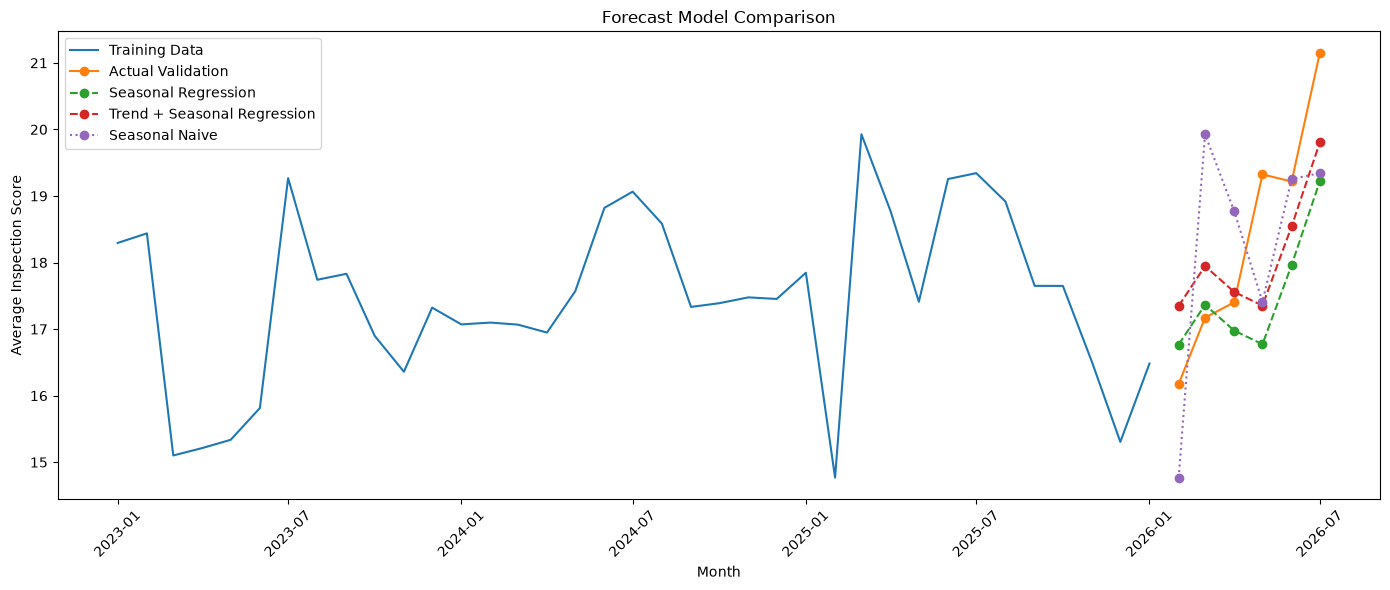

In [44]:
#visualizing forecasts against actual values
plt.figure(figsize=(14, 6))

plt.plot(
    train['MONTH'],
    train['Score'],
    label='Training Data'
)

plt.plot(
    valid['MONTH'],
    valid['Score'],
    marker='o',
    label='Actual Validation'
)

plt.plot(
    valid['MONTH'],
    valid['SEASONAL'],
    marker='o',
    linestyle='--',
    label='Seasonal Regression'
)

plt.plot(
    valid['MONTH'],
    valid['TREND_SEASONAL'],
    marker='o',
    linestyle='--',
    label='Trend + Seasonal Regression'
)

plt.plot(
    valid['MONTH'],
    valid['NAIVE'],
    marker='o',
    linestyle=':',
    label='Seasonal Naive'
)

plt.title('Forecast Model Comparison')
plt.xlabel('Month')
plt.ylabel('Average Inspection Score')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

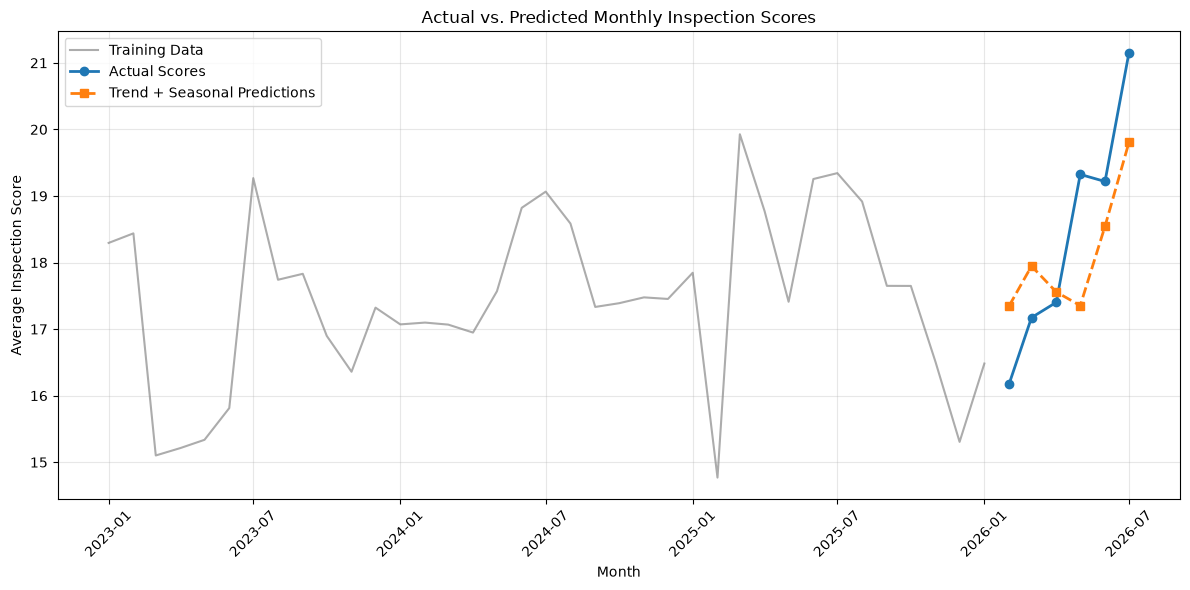

In [ ]:
#actual vs predicted inspection scores
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

#Historical training data
plt.plot(
    train['MONTH'],
    train['Score'],
    color='gray',
    alpha=0.65,
    label='Training Data'
)

#Actual validation values
plt.plot(
    valid['MONTH'],
    valid['Score'],
    marker='o',
    linewidth=2,
    label='Actual Scores'
)

#Predictions from best-performing model
plt.plot(
    valid['MONTH'],
    valid['TREND_SEASONAL'],
    marker='s',
    linestyle='--',
    linewidth=2,
    label='Trend + Seasonal Predictions'
)

plt.title('Actual vs. Predicted Monthly Inspection Scores')
plt.xlabel('Month')
plt.ylabel('Average Inspection Score')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

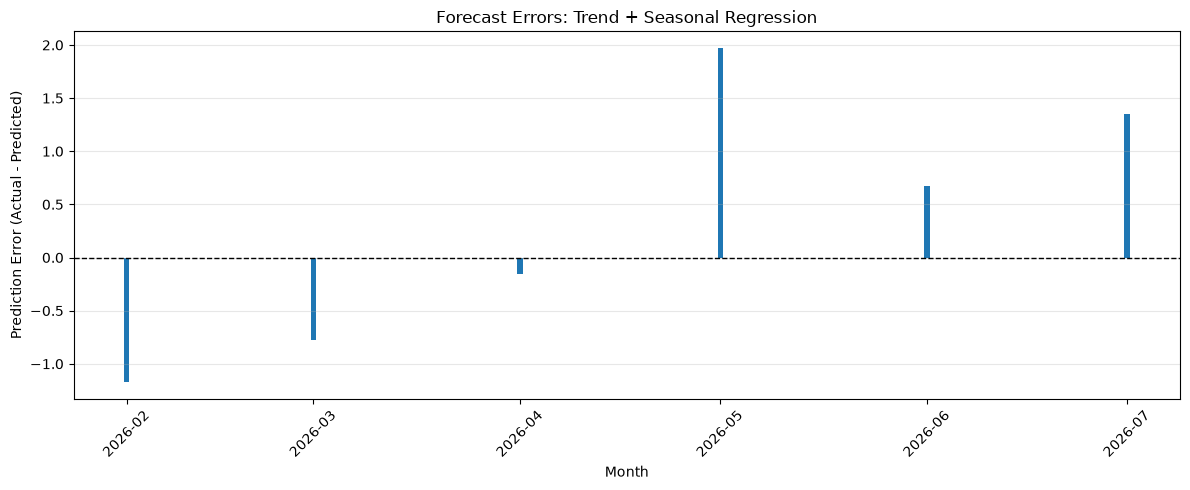

In [46]:
valid['ERROR'] = (
    valid['Score'] - valid['TREND_SEASONAL']
)

plt.figure(figsize=(12, 5))

plt.bar(
    valid['MONTH'],
    valid['ERROR']
)

plt.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=1
)

plt.title('Forecast Errors: Trend + Seasonal Regression')
plt.xlabel('Month')
plt.ylabel('Prediction Error (Actual - Predicted)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()